## PLUTO – Full Analysis

In this notebook, we perform a quantitative analysis on our final simulation runs.

### 0. Definitions

#### 0.1. Preamble

In [26]:
%%capture

%config InlineBackend.figure_formats = ['retina']

import os
import re
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=ResourceWarning)

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import pyPLUTO as pp

from matplotlib.colors import LogNorm, SymLogNorm, TwoSlopeNorm, Normalize
from matplotlib.ticker import ScalarFormatter, FixedLocator, FuncFormatter, NullFormatter, MaxNLocator
from mpl_toolkits.axes_grid1 import ImageGrid

from scipy import signal
from scipy.ndimage import uniform_filter1d

import statsmodels.api as sm

plt.rcParams['axes.prop_cycle'] = plt.cycler(color=["steelblue", "olivedrab", "goldenrod", "firebrick", "rebeccapurple"])
plt.rcParams['figure.figsize'] = [8,5]
plt.rcParams['figure.constrained_layout.use'] = True
plt.rcParams['legend.frameon'] = False
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True

def plain_log(ax, axis='x', mantissas=(1, 2, 3, 4, 6)):
    a = ax.xaxis if axis == 'x' else ax.yaxis
    lo, hi = sorted(ax.get_xlim() if axis == 'x' else ax.get_ylim())
    ticks = [m * 10.0**k for k in range(int(np.floor(np.log10(lo))) - 1, int(np.ceil(np.log10(hi))) + 1) for m in mantissas]
    a.set_major_locator(FixedLocator([t for t in ticks if lo <= t <= hi]))
    a.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:g}"))   # shortest plain form, 0.5, 2, 30
    a.set_minor_formatter(NullFormatter())

plt.plot()
plt.close()

#### 0.2. Configuration

In [2]:
MAIN_PATH = 'BH_VISC_RAD_HD_TRC_COMP_DF/'
MAIN_LABEL = '120 x 90'
MAIN_CACHE = os.path.join(MAIN_PATH, 'analysis_cache.npz')
MAIN_FORCE_REDUCE = False
MAIN_T_STEADY = None
MAIN_T_MIN, MAIN_T_MAX = None, None
MAIN_DT_LONG = None
MAIN_T_DENSE = None

REF_PATH = 'BH_VISC_RAD_HD_TRC_COMP/'
REF_LABEL = '90 x 45'
REF_CACHE = os.path.join(REF_PATH, 'analysis_cache.npz') if REF_PATH is not None else None
REF_FORCE_REDUCE = False
REF_T_STEADY = None
REF_T_MIN, REF_T_MAX = None, None
REF_DT_LONG = None
REF_T_DENSE = None

FULL_AVG_SPAN = 1.0e4
T_EARLY = [100, 200, 300, 400, 500, 600]

W_WINDOW = 2500.0
BLOCK = 1000.0
REF_FRAC = 0.2
Z_CRIT = 2.0
TOL_EQ = 0.2

R_WAVE = (4.0, 25.0)
WELCH_SEG = 6
WELCH_TSEG = 2500.0
R_PHASE_REF = 7.0
FIT_FRAC = 0.15
P_FUND_MIN = 0.3

R_PROFILES = [8.0, 12.0, 16.0]
R_ANG = (2.5, 3.0, 4.0, 6.0, 10.0, 20.0)
PROFILE_STRIDE = 4

R_BUDGET = (2.5, 25.0)

HEMI = 2.0

#### 0.3. Setting

The system reproduces a toy model Active Galactic Nucleus (AGN) with a central supermassive black hole (SMBH) where its event horizon is realized as a diode modified outflow boundary, where a Paczyński–Wiita potential mimics the Schwarzschild radius. Surrounding the SMBH is a viscous and radiative accretion disk, initially seeded and continuously injected as the Kluźniak-Kita solution to the Shakura-Sunyaev prescription. Both viscosity and opacity are pinned to the disk and disabled in the corona via a custom classifier that reconstructs a Lagrangian tracer, which fails with radiation enabled in the Eulerian PLUTO code.

#### 0.4. Units

Our implementation uses $GM = c = 1$ conventions, where $M = M_\text{SMBH} = 10^8 M_\odot \simeq 2.0\times10^{41}\,\text{g}$ and

$$r_g = \frac{GM}{c^2} \simeq 1.5\times 10^{13} \simeq 1.0\,\text{AU} \qquad v_0 = \sqrt{\frac{GM}{r_g}} = c \simeq 3.0\times 10^{10}\,\text{cm}\,\text{s}^{-1} \qquad t_g = \frac{r_g}{c} = \frac{GM}{c^3} \simeq 490\,\text{s} \qquad \rho_0 \simeq 5.8\times 10^{-10}\,\text{g}\,\text{cm}^{-3}$$

are set as units, from which we derive

$$p_0 = \epsilon_0 = \rho_0 c^2 \simeq 5.2\times10^{11}\,\text{dyn}\,\text{cm}^{-2}\qquad \dot{M}_0 = \rho_0 c r_g^2 \simeq 3.8\times10^{27}\,\text{g}\,\text{s}^{-1} \simeq 60\,M_\odot\,\text{yr}^{-1}\qquad L_0 = \rho_0 c^3 r_g^2 \simeq 3.4\times 10^{48}\,\text{erg}\,\text{s}^{-1} \simeq 8.8\times 10^{14}\,L_\odot$$

for pressure or energy density, mass flux, and luminosity. This means that distances are given in gravitational radii $r_g$ and times in $t_g$ timescales throughout.

#### 0.5. Constants

The gas temperature follows from an ideal fully ionized gas

$$T_g = \frac{\mu m_u c^2}{k}\,\frac{p}{\rho} \qquad \mu = \bigl( 2X + \tfrac{3}{4} Y + \tfrac{1}{2} Z \bigr)^{-1}$$

where abundancies are set as

$$X = 0.70 \qquad Z = 0.02 \qquad Y = 1 - X - Z = 0.28$$

for the mean molecular weight. On the other hand, the radiation temperature follows from its energy density as

$$T_r = \left( \frac{E_r}{a} \right)^{\!1/4} \qquad a = \frac{\sigma_\text{SB}}{\rho_0 c^3}$$

with the Stefan-Boltzmann constant. Radiation pressure is $p_r = E_r / 3$ in the optically thick limit, and PLUTO stores its flux $F$ in units of energy density, meaning $cF$ gives the physical flux.

#### 0.6. Model

The computational grid uses spherical $(r, \vartheta)$ coordinates, where $R = r\sin\vartheta$ and $z = r\cos\vartheta$ are cylindrical quantities, as well as axisymmetry and equatorialsymmetry, so that $\vartheta = [0, \pi / 2]$ gives the angular domain. Mechanics are Newtonian with a Paczyński–Wiita potential

$$\Phi(r) = -\frac{GM}{r - r_\text{S}} = -\frac{1}{r - 2}$$

with $r_\text{S} = 2r_g$ the Schwarzschild radius. Circular orbits in the midplane have

$$\Omega^2 = \frac{1}{R}\frac{\mathrm{d}\Phi}{\mathrm{d}R} = \frac{1}{R\,(R-2)^2}\qquad \ell = R^2\,\Omega\qquad \kappa^2 = \frac{1}{R^3}\frac{\mathrm{d}\left(R^4\Omega^2\right)}{\mathrm{d}R} = \Omega^2\,\frac{R - 6}{R - 2}$$

as angular velocity, specific angular momentum and epicyclic frequency. From this follows an innermost stable orbit (ISCO) defined by $\kappa^2 = 0$ at $R_\text{isco} = 6r_g$ from the singularity. The Newtonian Keplerian angular velocity $\Omega = R^{-3/2}$ is still used for the initial disk seeding as well as the disk versus corona classifier.

An adiabatic atmosphere in hydrostatic equilibrium with the Newtonian potential $\Phi(r) = -1/r$ and for $\gamma = C_p / C_v = 5/3$ adiabatic index

$$\rho_c(r) = \rho_c^{(0)}\, r^{-3/2} \qquad p_c(r) = \frac{2}{5}\,\rho_c^{(0)}\, r^{-5/2} \qquad \frac{p_c}{\rho_c} = \frac{\gamma-1}{\gamma}\,\frac{1}{r}$$

defines the corona and ensures numerical stability. The Kluźniak & Kita polytropic disk with aspect ratio $\epsilon = H/R$ follows from

$$C(r,\vartheta) = \frac{2}{5\epsilon^2}\left[\frac{1}{r} - \left(1 - \frac{5}{2}\epsilon^2\right)\frac{1}{R}\right] \qquad \rho_d = C^{3/2} \qquad p_d = \epsilon^2\, C^{5/2}$$

and occupies all cells where $p_d \geq p_c$ and $R > R_d$ hold. Its velocities include the viscous inflow of the $\alpha$ disk

$$v_\varphi = \frac{1}{\sqrt{R}}\left[\sqrt{1 - \frac{5}{2}\epsilon^2} + \frac{2}{3}\epsilon^2\alpha^2\lambda\left(1 - \frac{6}{5\,\epsilon^2\tan^2\vartheta}\right)\right]\qquad v_r = -\frac{\alpha\,\epsilon^2}{\sin\vartheta\,\sqrt{R}}\left[10 - \frac{32}{3}\lambda\alpha^2 - \lambda\left(5 - \frac{1}{\epsilon^2\tan^2\vartheta}\right)\right]$$

with $\lambda = \dfrac{11}{5}\left(1 + \dfrac{64}{25}\alpha^2\right)^{-1}$ and $v_\vartheta = 0$ while in the corona all velocities vanish.

Radiation is initially seeded to share the analytic disk pressure with the gas at a common temperature

$$\frac{\rho\,T}{K_T} + \frac{a\,T^4}{3} = p_d \qquad p_\mathrm{g} = \frac{\rho\,T}{K_T} \qquad E_r = a\,T^4 \qquad \boldsymbol{F} = 0$$

where $K_T = \mu m_u c^2/k$ is used, and the corona gets assigned an initial $E_r = 10^{-16}$ corresponding to the minimun radiation energy.

Only the shear viscosity $\nu_1$ of an $\alpha$ prescription with the initial analytic sound speed acts

$$\nu_1 = \frac{2}{3}\,\rho\,\alpha\, c_s^2\, R^{3/2}\, f \qquad c_s^2 = \epsilon^2 \max(C, 0)$$

while the bulk viscosity $\nu_2$ is neglected

$$\nu_2 = 0$$

where $f$ is the tracer replacement classifier. In the midplane $C = 1/R$ so the kinematic viscosity is

$$\nu(R) = \frac{\nu_1}{\rho} = \frac{2}{3}\,\alpha\,\epsilon^2\, R^{1/2}$$

and the viscous heating rate per volume is $q^+ = \nu_1 \left(R\,\partial\Omega/\partial R\right)^2$ from the dominant $r\varphi$ stress. Since the analytic sound speed is fixed, viscous heating does not respond to the thermal state of the disk, which suppresses the thermal and viscous instability of radiation pressure dominated disks. A self consistent $\alpha$ prescription uses the local total pressure for

$$\nu_1 = \frac{2}{3}\,\rho\,\alpha\,c_s^2\,R^{3/2} f \qquad c_s^2 = \frac{p + E_r/3}{\rho}$$

capped in hot and thin gas.

A continuous classifier $f \in [0,1]$ multiplies a density and a rotation criterion

$$f = \sigma\!\left(\frac{s - 1/6}{0.3}\right)\,\sigma\!\left(\frac{|v_\varphi|\sqrt{R} - 0.5}{0.1}\right) \qquad
s = \frac{\log\rho - \log\bar\rho_c(r)}{\max\left[\log(\bar\rho_d/\bar\rho_c),\ 0.5\right]} \qquad \sigma(x) = \frac{1}{1 + e^{-x}}$$

with reference profiles $\bar\rho(r)$ of the corona and the disk in logarithmic radial bins. They are volume averages weighted by $f$ of each bin or, optionally, the bin maximum density and the geometric mean density above $z/R = 0.5$ to remove the self referntial feature of the method. New estimates $\hat\rho$ enter through an exponential moving average with time constant $\tau = 6\,t_g$ via

$$\bar\rho^{\,n+1} = \alpha\,\hat\rho^{\,n+1} + (1 - \alpha)\,\bar\rho^{\,n} \qquad \alpha = 1 - e^{-\Delta t_u/\tau}$$

with $\Delta t_u$ the time between updates. An estimate therefore decays as $e^{-(t - t')/\tau}$ independent of resolution and update
cadence. Bins whose span falls below $0.5\,\text{dex}$ take the references of the nearest bin with a sufficient span. Previous runs used a fixed $\alpha = 0.05$ per step without these guards.

With $\rho$ and $T$ in CGS as well as a $T \geq 10^4\,\text{K}$ clamped gas temperature, we get

$$\kappa_\mathrm{es} = 0.20\,(1+X)\,\mathrm{cm^2\,g^{-1}}$$

for electron scattering and

$$\kappa_\mathrm{ff+bf} = \left(K_\mathrm{ff} + K_\mathrm{bf}\right) \rho\, T^{-7/2} \qquad K_\mathrm{ff} = 3.68 \times 10^{22}\,(1-Z)(1+X) \qquad K_\mathrm{bf} = 4.34 \times 10^{25}\, \frac{Z(1+X)}{10}$$

following Kramers law. Compton energy exchange enters as an effective absorption opacity

$$\kappa_C = \kappa_\mathrm{es}\, \frac{4 k T_r^4}{m_e c^2\,(T_g + T_r)(T_g^2 + T_r^2)} \;\; (T_g \leq T_\mathrm{max}) \qquad
\kappa_C = \kappa_\mathrm{es}\, \frac{4 k T_r^4\,(T_\mathrm{max} - T_r)}{m_e c^2\,(T_g^4 - T_r^4)} \;\; (T_g > T_\mathrm{max})$$

that with $T_\mathrm{max} = 10^9\,\text{K}$ reproduces the nonrelativistic rate $\rho\,\kappa_\mathrm{es} c\, E_r\, 4k (T_g - T_r)/(m_e c^2)$ exactly. We define

$$\kappa_a = g_v\, f_d \left(\kappa_\mathrm{ff+bf} + \kappa_C\right) \qquad \kappa_s = g_v \left(\kappa_\mathrm{es} - f_d\, \kappa_C\right) \qquad f_d = \max\!\left(0, \frac{f - 0.05}{0.95}\right) \qquad g_v = \sigma\!\left(-\frac{|\boldsymbol{v}|/c - 0.9}{0.03}\right)$$

such that absorption and Compton act only in the disk, while Thomson scattering applies everywhere, and $g_v$ decouples matter and radiation in the plunging region, where the gas moves faster than the nonrelativistic radiation module can handle. Opacities are per unit mass and converted with $\rho_0 R_g$ to code units.

The Eddington luminosity and accretion rate are given as

$$L_\mathrm{E} = \frac{4\pi G M c}{\kappa_\mathrm{es}} \qquad\dot M_\mathrm{E} = \frac{L_\mathrm{E}}{\eta\, c^2}$$

where $\eta = 1/16$ derives from the binding energy at the ISCO of the Paczyński–Wiita potential.

In this PLUTO build radiation is not advected with the gas, does no work on it and exerts no drag. Only the comoving source terms
$\rho\kappa_a c\,(aT_g^4 - E_r)$ and $\rho(\kappa_a+\kappa_s)\boldsymbol{F}$ couple the two. Compression of the gas does not heat the
radiation, which matters for the wave diagnostics.

At the inner domain boundary, all variables are copied from the first active cell, a diode enforces $v_r \leq 0$ and also floors $\rho \geq \rho_\mathrm{fl}$ and $p \geq 10^{-3}\rho_\mathrm{fl}$ while radiation $E_r$ is copied and $F_r \leq 0$ is set. Beyond the outer edge, density is extrapolated as $\rho_i = \rho_{i-1}\,(r_i/r_{i-1})^{a}$ with a Van Leer limited, negative slope $a$ and a pressure adiabatic $p = p_N\,(\rho/\rho_N)^\gamma$ while $v_r$ and $v_\vartheta$ are copied, and $v_\varphi$ is extrapolated. Within $|\vartheta - \pi/2| \leq \arctan(1.25\,\epsilon)$ the analytic disk density and velocities are reinjected. Within $|\vartheta - \pi/2| \geq \arctan(3\,\epsilon)$ coronal inflow is blocked by setting velocities to zero where $v_r < 0$ is fulfilled. Radiation $E_r$ gets copied and $F_r \geq 0$ is used again. The grid at $\vartheta = 0$ is axisymmetric and takes on at $\vartheta = \pi/2$ equatorial symmetry. Inside the domain, density is $\rho \geq \rho_\mathrm{fl} = 5\times10^{-7}$ which thereby raises $\rho$ at fixed sound speed and momentum, and $T_g \geq 10^4\ \mathrm{K}$ is set. Both floors add mass or energy, which can be quantified.

#### 0.7. Characteristics

For a thin disk with $H = \epsilon R$ and midplane sound speed $c_s^{(0)} = \epsilon\,R^{-1/2}$ the relevant timescales are

$$
t_\mathrm{orb} = \frac{2\pi}{\Omega} \qquad
t_\mathrm{th} = \frac{1}{\alpha\,\Omega_N} \qquad
t_\nu = \frac{R^2}{\nu} = \frac{3}{2}\,\frac{R^{3/2}}{\alpha\,\epsilon^2} \qquad
t_\mathrm{cs} = \frac{R}{c_s^{(0)}} \qquad
t_\mathrm{diff} \simeq \frac{\tau\, H}{c}
$$

where $$\tau = \frac{\kappa\,\Sigma}{2}$$ 

defines the optical depth from the midplane to the disk surface. The viscous time sets how far out the disk can reach inflow equilibrium within a given run time as $R_\nu(t)$ with $t_\nu(R_\nu) = t$ while the diffusion time needs the measured surface density.

In [3]:
CONST_G     = 6.6726e-8
CONST_c     = 2.99792458e10
CONST_amu   = 1.66053886e-24
CONST_kB    = 1.3806505e-16
CONST_sigma = 5.67051e-5
CONST_Msun  = 1.989e33
YEAR        = 3.15576e7
DAY         = 86400.0

def read_definitions(path):
    with open(os.path.join(path, 'definitions.h')) as fh:
        txt = fh.read()
    rho0 = re.search(r'#define\s+UNIT_DENSITY\s+([0-9.eE+-]+)', txt)
    mbh = re.search(r'#define\s+BH_MASS\s+\(\s*([0-9.eE+-]+)\s*\*\s*([0-9.eE+-]+)\s*\)', txt)
    rho0 = float(rho0.group(1)) if rho0 else 5.8e-10
    mbh = float(mbh.group(1)) * float(mbh.group(2)) if mbh else 1.0e8 * CONST_Msun
    return rho0, mbh

def read_parameters(path):
    params, inside = {}, False
    with open(os.path.join(path, 'pluto.ini')) as fh:
        for line in fh:
            s = line.strip()
            if s.startswith('['):
                inside = (s == '[Parameters]')
                continue
            if inside and s and not s.startswith('#'):
                key, val = s.split()[:2]
                params[key] = float(val)
    return params

RHO0, M_BH = read_definitions(MAIN_PATH)
PAR = read_parameters(MAIN_PATH)

if REF_PATH is not None:
    same = (read_definitions(REF_PATH) == (RHO0, M_BH)) and (read_parameters(REF_PATH) == PAR)
    print(f"reference run {REF_PATH}: " + ("same units and parameters\n" if same else "units or parameters differ\n"))

GAMMA = 5.0 / 3.0
X_H, Z_M = 0.70, 0.02
Y_HE = 1.0 - X_H - Z_M
MU = 1.0 / (2.0 * X_H + 0.75 * Y_HE + 0.5 * Z_M)

ALPHA = PAR['BETAV']
EPS = PAR['EPS']
RHOC = PAR['RHOC']
RD = PAR['RD']
DFLOOR = PAR['DFLOOR']

R_G = CONST_G * M_BH / CONST_c**2
T_G = R_G / CONST_c
P0 = RHO0 * CONST_c**2
MDOT0 = RHO0 * CONST_c * R_G**2
L0 = RHO0 * CONST_c**3 * R_G**2

K_T = MU * CONST_amu * CONST_c**2 / CONST_kB
A_RAD = 4.0 * CONST_sigma / CONST_c / P0

KAPPA_ES = 0.2 * (1.0 + X_H)
ETA = 1.0 / 16.0
L_EDD = 4.0 * np.pi * CONST_G * M_BH * CONST_c / KAPPA_ES
MDOT_EDD = L_EDD / (ETA * CONST_c**2)

print(f"R_g = {R_G:.4e} cm,   t_g = {T_G:.1f} s,   rho_0 = {RHO0:.2e} g/cm^3,   p_0 = {P0:.3e} erg/cm^3")
print(f"Mdot_0 = {MDOT0:.3e} g/s = {MDOT0 * YEAR / CONST_Msun:.3e} Msun/yr,   L_0 = {L0:.3e} erg/s")
print(f"L_Edd = {L_EDD:.3e} erg/s = {L_EDD / L0:.3e} L_0,   Mdot_Edd = {MDOT_EDD * YEAR / CONST_Msun:.3f} Msun/yr = {MDOT_EDD / MDOT0:.3e} Mdot_0")
print(f"mu = {MU:.4f},   K_T = {K_T:.4e} K,   a = {A_RAD:.4e} (code)")
print(f"alpha = {ALPHA},   eps = {EPS},   rho_c = {RHOC},   R_d = {RD},   floor = {DFLOOR}")

reference run BH_VISC_RAD_HD_TRC_COMP/: same units and parameters

R_g = 1.4767e+13 cm,   t_g = 492.6 s,   rho_0 = 5.80e-10 g/cm^3,   p_0 = 5.213e+11 erg/cm^3
Mdot_0 = 3.792e+27 g/s = 6.016e+01 Msun/yr,   L_0 = 3.408e+48 erg/s
L_Edd = 1.471e+46 erg/s = 4.315e-03 L_0,   Mdot_Edd = 4.154 Msun/yr = 6.905e-02 Mdot_0
mu = 0.6173,   K_T = 6.6725e+12 K,   a = 1.4514e-26 (code)
alpha = 0.5,   eps = 0.1,   rho_c = 0.01,   R_d = 6.0,   floor = 5e-07


In [4]:
def omega_pw(R):
    return 1.0 / ((R - 2.0) * np.sqrt(R))

def omega_newton(R):
    return R**-1.5

def kappa_epi(R):
    return omega_pw(R) * np.sqrt(np.clip((R - 6.0) / (R - 2.0), 0.0, None))

def nu_kin(R):
    return 2.0 / 3.0 * ALPHA * EPS**2 * np.sqrt(R)

def cs0(R):
    return EPS / np.sqrt(R)

def t_orbit(R):    return 2.0 * np.pi / omega_pw(R)
def t_thermal(R):  return 1.0 / (ALPHA * omega_newton(R))
def t_viscous(R):  return R**2 / nu_kin(R)
def t_sound(R):    return R / cs0(R)

def r_viscous(t):
    return (2.0 * ALPHA * EPS**2 * np.asarray(t, dtype=float) / 3.0)**(2.0 / 3.0)

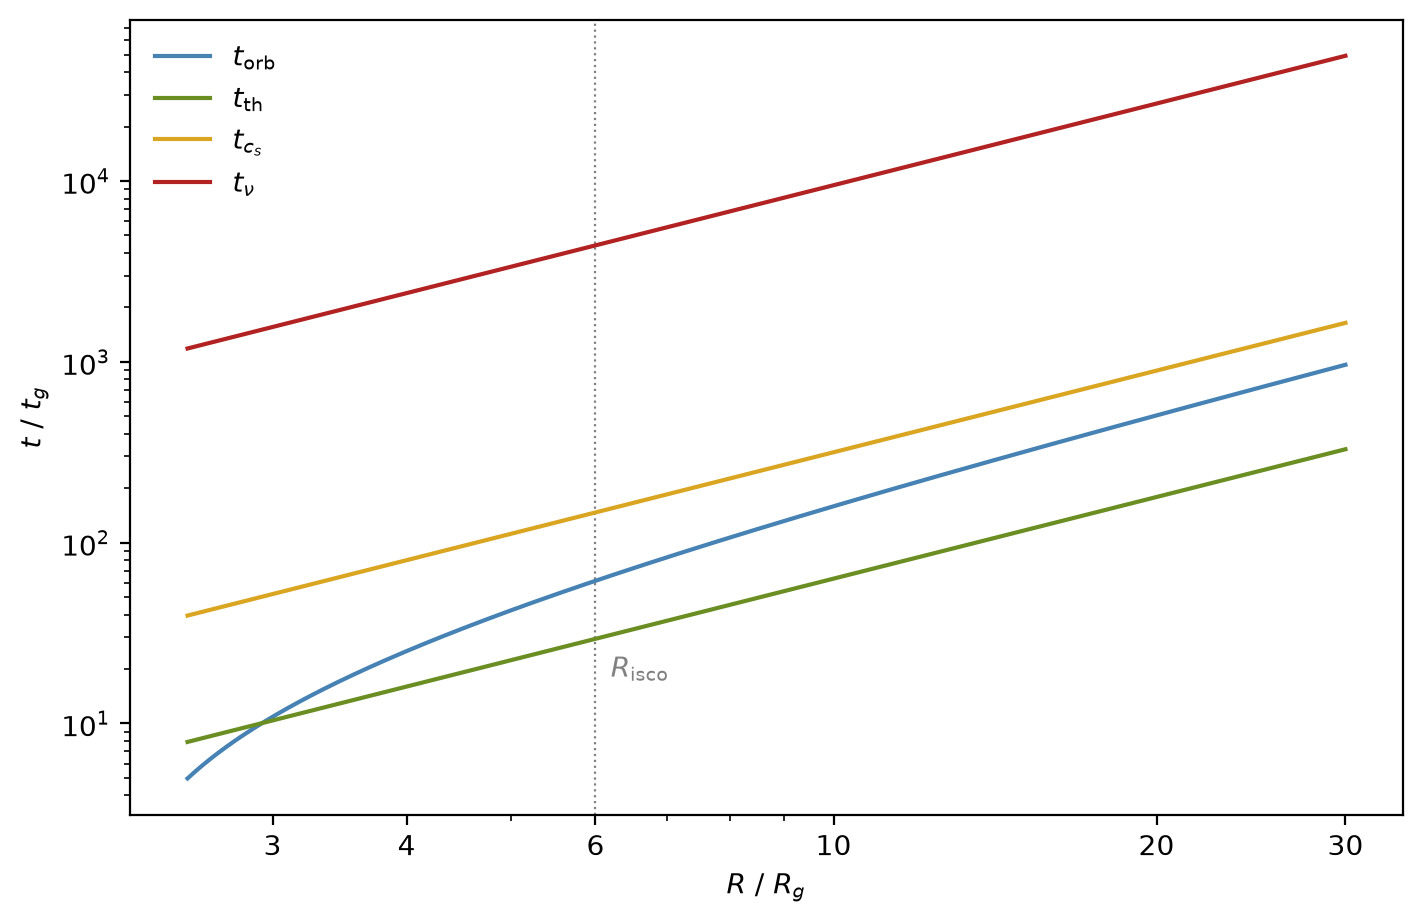

R =  6:  t_orb =     61.6   t_th =    29.4   t_cs =   147.0   t_nu =    4409.1   [t_g]
R = 10:  t_orb =    159.0   t_th =    63.2   t_cs =   316.2   t_nu =    9486.8   [t_g]
R = 15:  t_orb =    316.4   t_th =   116.2   t_cs =   580.9   t_nu =   17428.4   [t_g]
R = 20:  t_orb =    505.8   t_th =   178.9   t_cs =   894.4   t_nu =   26832.8   [t_g]
R = 30:  t_orb =    963.6   t_th =   328.6   t_cs =  1643.2   t_nu =   49295.0   [t_g]


In [5]:
R_plot = np.geomspace(2.5, 30, 300)

fig, ax = plt.subplots(figsize=[7, 4.5])

ax.axvline(6.0, color='gray', lw=0.8, ls=':')

ax.plot(R_plot, t_orbit(R_plot), label=r'$t_\mathrm{orb}$')
ax.plot(R_plot, t_thermal(R_plot), label=r'$t_\mathrm{th}$')
ax.plot(R_plot, t_sound(R_plot), label=r'$t_{c_s}$')
ax.plot(R_plot, t_viscous(R_plot), label=r'$t_\nu$')

ax.text(6.2, 18, r'$R_\mathrm{isco}$', color='gray')

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xticks([3, 4, 6, 10, 20, 30])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())

ax.set_xlabel(r'$R\ /\ R_g$')
ax.set_ylabel(r'$t\ /\ t_g$')

ax.legend()

plt.show()

for R in [6, 10, 15, 20, 30]:
    print(f"R = {R:2d}:  t_orb = {t_orbit(R):8.1f}   t_th = {t_thermal(R):7.1f}   t_cs = {t_sound(R):7.1f}   t_nu = {t_viscous(R):9.1f}   [t_g]")

#### 0.8. Helpers

Regarding geometry, all edges come from the grid output, so all integrals use

$$\Delta\Omega_j = 2\pi\left(\cos\vartheta_{j-1/2} - \cos\vartheta_{j+1/2}\right)\qquad
\Delta V_{ij} = \frac{r_{i+1/2}^3 - r_{i-1/2}^3}{3}\,\Delta\Omega_j$$

for the exact cell volumes and solid angles.

Every frame is reduced to radial profiles and global scalars. Sums ran over the simulated hemisphere are multiplied full sphere

$$\Sigma(r) = 2\sum_j \rho_{ij}\, r_i\, \Delta\vartheta_j \qquad
\dot M(r) = 2\, r^2 \sum_j \rho_{ij}\, v_{r,ij}\, \Delta\Omega_j \qquad
\dot M_\mathrm{acc} = -\dot M$$

with disk and corona parts weighted by $f$ and $1 - f$ respectively, and inflow and outflow parts split by the $v_r$ sign. Then $\Sigma$ is the column along $\vartheta$ at fixed $r$ which equals the vertical column $\int\rho\,\mathrm{d}z$ of a thin disk. The disk aspect ratio
is the $f\rho$ weighted root mean square height

$$
\frac{H}{R}(r) = \left[\frac{\sum_j f\rho\, \cot^2\vartheta_j\, \Delta\vartheta_j}{\sum_j f\rho\, \Delta\vartheta_j}\right]^{1/2}
$$

and

$$
M = 2\sum \rho\,\Delta V \qquad M_d = 2\sum f\rho\,\Delta V \qquad E_\mathrm{rad} = 2\sum E_r\,\Delta V \qquad
E_\mathrm{th} = 2\sum \frac{p}{\gamma - 1}\,\Delta V \qquad E_\mathrm{kin} = 2\sum \tfrac{1}{2}\rho v^2\,\Delta V \qquad
L(r) = 2\, r^2 \sum_j F_{r,ij}\, \Delta\Omega_j
$$

are the global scalars.

The mass of every radial shell is stored in two halves, inside and outside the $r_i$ cell centre, so that the mass between any two
cell centres follows exactly, useful for the control volume of the mass budget.

The optical depth from the pole along $\vartheta$ at fixed $r$ is $\tau(r,\vartheta) = \int_0^\vartheta \rho\,(\kappa_a +
\kappa_s)\, r\, \mathrm{d}\vartheta'$ and $\tau = 1$ marks the photosphere seen from above.

In [6]:
def read_grid(path):
    with open(os.path.join(path, 'grid.out')) as fh:
        lines = [l for l in fh if not l.startswith('#')]
    edges, k = [], 0
    while k < len(lines) and lines[k].strip():
        n = int(lines[k].split()[0]); k += 1
        block = np.array([[float(v) for v in lines[k + m].split()[1:3]] for m in range(n)])
        edges.append(np.append(block[:, 0], block[-1, 1]))
        k += n
    return edges

def read_outputs(path):
    entries = {}
    with open(os.path.join(path, 'dbl.out')) as fh:
        for line in fh:
            s = line.split()
            if len(s) > 1:
                entries[int(s[0])] = float(s[1])
    outs = np.array(sorted(entries))
    return outs, np.array([entries[n] for n in outs])

def make_geometry(path):
    R_E, TH_E = read_grid(path)[:2]
    R_C = 0.5 * (R_E[1:] + R_E[:-1])
    TH_C = 0.5 * (TH_E[1:] + TH_E[:-1])
    DOM = 2.0 * np.pi * (np.cos(TH_E[:-1]) - np.cos(TH_E[1:]))
    R_MID_E = np.concatenate([[R_C[0]], R_E[1:-1], [R_C[-1]]])
    return dict(
        R_E=R_E, TH_E=TH_E, R_C=R_C, TH_C=TH_C, NR=R_C.size, NTH=TH_C.size,
        DR=np.diff(R_E), DTH=np.diff(TH_E), DOM=DOM,
        DV=((R_E[1:]**3 - R_E[:-1]**3) / 3.0)[:, None] * DOM[None, :],
        COT=np.cos(TH_C) / np.sin(TH_C),
        DV_LO=((R_C**3 - R_E[:-1]**3) / 3.0)[:, None] * DOM[None, :],
        DV_HI=((R_E[1:]**3 - R_C**3) / 3.0)[:, None] * DOM[None, :],
        DV_MID=((R_MID_E[1:]**3 - R_MID_E[:-1]**3) / 3.0)[:, None] * DOM[None, :],
    )

MAIN_GEO = make_geometry(MAIN_PATH)
REF_GEO = make_geometry(REF_PATH) if REF_PATH is not None else None

R_E, TH_E, R_C, TH_C = (MAIN_GEO[k] for k in ['R_E', 'TH_E', 'R_C', 'TH_C'])
NR, NTH = MAIN_GEO['NR'], MAIN_GEO['NTH']
DR, DTH, DOM, DV, COT = (MAIN_GEO[k] for k in ['DR', 'DTH', 'DOM', 'DV', 'COT'])
DV_LO, DV_HI, DV_MID = (MAIN_GEO[k] for k in ['DV_LO', 'DV_HI', 'DV_MID'])

for path, geo in [(MAIN_PATH, MAIN_GEO), (REF_PATH, REF_GEO)]:
    if geo is None:
        continue
    outs, times = read_outputs(path)
    print(f"{path}: grid {geo['NR']} x {geo['NTH']},  r in [{geo['R_E'][0]}, {geo['R_E'][-1]}],"
          f"  theta in [{geo['TH_E'][0]:.4f}, {geo['TH_E'][-1]:.4f}],  {outs.size} outputs,  t in [{times[0]:.1f}, {times[-1]:.1f}]")

VARS = ['rho', 'vx1', 'vx2', 'vx3', 'prs', 'enr', 'fr1', 'fr2', 'diskfrac', 'nu', 'kappa_abs', 'kappa_scat']

def load(n, path=MAIN_PATH, geo=MAIN_GEO):
    D = pp.Load(nout=int(n), path=path)
    shape = (geo['NR'], geo['NTH'])
    out = {}
    for v in VARS:
        a = np.asarray(getattr(D, v), dtype=float)
        assert a.shape == shape, f"{v} has shape {a.shape}, expected {shape}"
        out[v] = a
    return out

def gas_temperature(F):
    return K_T * F['prs'] / F['rho']

def rad_temperature(F):
    return (np.clip(F['enr'], 0.0, None) / A_RAD)**0.25

def optical_depth_from_pole(F, g=MAIN_GEO):
    dtau = F['rho'] * (F['kappa_abs'] + F['kappa_scat']) * g['R_C'][:, None] * g['DTH'][None, :]
    return np.cumsum(dtau, axis=1)

BH_VISC_RAD_HD_TRC_COMP_DF/: grid 120 x 90,  r in [2.1, 30.0],  theta in [0.0000, 1.5708],  2601 outputs,  t in [0.0, 40000.0]
BH_VISC_RAD_HD_TRC_COMP/: grid 90 x 45,  r in [2.1, 30.0],  theta in [0.0000, 1.5708],  1001 outputs,  t in [0.0, 50000.0]


In [7]:
def reduce_frame(F, g):
    R_C, DTH, DOM, COT, DV = g['R_C'], g['DTH'], g['DOM'], g['COT'], g['DV']
    DV_LO, DV_HI, DV_MID = g['DV_LO'], g['DV_HI'], g['DV_MID']
    rho, vr, f = F['rho'], F['vx1'], F['diskfrac']
    col = R_C[:, None] * DTH[None, :]
    flux = rho * vr * R_C[:, None]**2 * DOM[None, :]
    w = f * rho * DTH[None, :]
    v2 = F['vx1']**2 + F['vx2']**2 + F['vx3']**2
    i20 = int(np.argmin(np.abs(R_C - 20.0)))
    return dict(
        sigma      = HEMI * np.sum(rho * col, axis=1),
        sigma_d    = HEMI * np.sum(f * rho * col, axis=1),
        mdot       = HEMI * np.sum(flux, axis=1),
        mdot_d     = HEMI * np.sum(f * flux, axis=1),
        mdot_c     = HEMI * np.sum((1.0 - f) * flux, axis=1),
        mdot_out   = HEMI * np.sum(np.where(vr > 0, flux, 0.0), axis=1),
        mdot_in    = HEMI * np.sum(np.where(vr < 0, flux, 0.0), axis=1),
        hr         = np.sqrt(np.sum(w * COT[None, :]**2, axis=1) / np.maximum(np.sum(w, axis=1), 1e-300)),
        rho_mid    = rho[:, -1],
        prs_mid    = F['prs'][:, -1],
        enr_mid    = F['enr'][:, -1],
        vr_mid     = vr[:, -1],
        vphi_mid   = F['vx3'][:, -1],
        nu_mid     = F['nu'][:, -1],
        f_mid      = F['diskfrac'][:, -1],
        m_lo       = HEMI * np.sum(rho * DV_LO, axis=1),
        m_hi       = HEMI * np.sum(rho * DV_HI, axis=1),
        M          = HEMI * np.sum(rho * DV),
        M_mid      = HEMI * np.sum(rho * DV_MID),
        M_d        = HEMI * np.sum(f * rho * DV),
        M_c        = HEMI * np.sum((1.0 - f) * rho * DV),
        E_rad      = HEMI * np.sum(F['enr'] * DV),
        E_th       = HEMI * np.sum(F['prs'] / (GAMMA - 1.0) * DV),
        E_kin      = HEMI * np.sum(0.5 * rho * v2 * DV),
        L_out      = HEMI * R_C[-1]**2 * np.sum(F['fr1'][-1, :] * DOM),
        L_20       = HEMI * R_C[i20]**2 * np.sum(F['fr1'][i20, :] * DOM),
    )

CACHE_KEYS = set(reduce_frame({v: np.ones((MAIN_GEO['NR'], MAIN_GEO['NTH'])) for v in VARS}, MAIN_GEO))

def read_cache(cache, force, nr):
    if force or not os.path.exists(cache):
        return None
    with np.load(cache) as Z:
        old = {key: Z[key] for key in Z.files}
    if not CACHE_KEYS <= set(old) or old['r'].size != nr:
        print(f"cache {cache} incomplete for this notebook version, rebuilding it from all outputs")
        return None
    return old

def update_cache(path, geo, cache, force):
    outs_all, times_all = read_outputs(path)
    old = read_cache(cache, force, geo['NR'])
    index = {}
    if old is not None:
        index = {int(n): k for k, n in enumerate(old['outs'])}
    rows, n_new = [], 0
    for n, t in zip(outs_all, times_all):
        k = index.get(int(n))
        if k is not None and np.isclose(old['t'][k], t, rtol=1e-9, atol=1e-6):
            rows.append({key: old[key][k] for key in CACHE_KEYS})
        else:
            rows.append(reduce_frame(load(n, path, geo), geo))
            n_new += 1
            if n_new % 100 == 0:
                print(f"{path}: reduced {n_new} new outputs, now at {n} (t = {t:.0f})")
    C = {key: np.array([row[key] for row in rows]) for key in CACHE_KEYS}
    C['t'], C['outs'], C['r'] = times_all, outs_all, geo['R_C']
    if n_new > 0 or old is None or old['outs'].size != outs_all.size:
        np.savez_compressed(cache, **C)
    print(f"cache {cache}: {outs_all.size} outputs, {n_new} newly reduced")
    return C

C_MAIN = update_cache(MAIN_PATH, MAIN_GEO, MAIN_CACHE, MAIN_FORCE_REDUCE)
C_REF = update_cache(REF_PATH, REF_GEO, REF_CACHE, REF_FORCE_REDUCE) if REF_PATH is not None else None

cache BH_VISC_RAD_HD_TRC_COMP_DF/analysis_cache.npz: 2601 outputs, 0 newly reduced
cache BH_VISC_RAD_HD_TRC_COMP/analysis_cache.npz: 1001 outputs, 0 newly reduced


#### 0.9. Sampling

The runs may mix output cadences, so two series are built from the cache, both with $t_\mathrm{min} \leq t \leq t_\mathrm{max}$ restriction. Contained in the long series are outputs at integer multiples of the set coarse step, a uniform sampling of the whole run. Relaxation, time averages and the snapshots of the evolution use it. On the other hand, the dense series is the final segment with a finer cadence, if there is one, starting at set threshold. It lies in the steady state, and the spectra, phase speeds and mass budget use it. Without a dense segment they use the steady window of the long series instead. Both runs are sampled the same way, each with its own switches.

In [8]:
def cadences(t):
    dts = np.diff(t)
    dts = dts[dts > 0]
    rounded = np.array([float(f"{x:.3g}") for x in dts])
    values, counts = np.unique(rounded, return_counts=True)
    frequent = values[counts >= 10]
    return frequent if frequent.size else np.array([np.median(dts)])

def long_indices(t, dt_long):
    phase = t / dt_long
    on_grid = np.abs(phase - np.round(phase)) < 0.02
    idx = np.nonzero(on_grid)[0]
    _, first = np.unique(np.round(phase[idx]).astype(int), return_index=True)
    return idx[first]

def dense_indices(t, dt_long, t_dense=None):
    fine = cadences(t).min()
    if t_dense is None:
        if fine > 0.5 * dt_long:
            return None
        jumps = np.nonzero(np.diff(t) > 1.5 * fine)[0]
        t_dense = t[jumps[-1] + 1] if jumps.size else t[0]
    idx = np.nonzero(t >= t_dense)[0]
    return idx if idx.size > 20 else None

def slice_cache(Cx, idx):
    n = Cx['t'].size
    return {key: (val[idx] if (np.ndim(val) > 0 and val.shape[0] == n and key != 'r') else val) for key, val in Cx.items()}

def make_series(Cx, label, dt_long=None, t_dense=None, t_min=None, t_max=None):
    t_all = Cx['t']
    keep = np.ones(t_all.size, dtype=bool)
    if t_min is not None: keep &= t_all >= t_min
    if t_max is not None: keep &= t_all <= t_max
    Cx = slice_cache(Cx, np.nonzero(keep)[0])
    t_all = Cx['t']
    dt_long = dt_long or cadences(t_all).max()
    il = long_indices(t_all, dt_long)
    gaps = np.diff(t_all[il]) > 1.5 * dt_long
    if gaps.any():
        print(f"WARNING {label}: {gaps.sum()} gaps in the long series, e.g. after t = {t_all[il][:-1][gaps][0]:.0f}")
    idn = dense_indices(t_all, dt_long, t_dense)
    run = dict(label=label, r=Cx['r'], all=Cx, C=slice_cache(Cx, il), dt=dt_long,
               D=None if idn is None else slice_cache(Cx, idn),
               dt_d=None if idn is None else float(np.median(np.diff(t_all[idn]))))
    run['t'] = run['C']['t']
    msg = f"{label}: long series {run['t'].size} frames at cadence {dt_long:g}, t in [{run['t'][0]:.0f}, {run['t'][-1]:.0f}]"
    if run['D'] is not None:
        msg += f" and dense segment {run['D']['t'].size} frames at cadence {run['dt_d']:g} from t = {run['D']['t'][0]:.0f}"
    print(msg)
    return run

RUN = make_series(C_MAIN, MAIN_LABEL, MAIN_DT_LONG, MAIN_T_DENSE, MAIN_T_MIN, MAIN_T_MAX)
RUN['dth_mid'] = MAIN_GEO['DTH'][-1]
C, T, DT_OUT = RUN['C'], RUN['t'], RUN['dt']

REF = None
if REF_PATH is not None:
    REF = make_series(C_REF, REF_LABEL, REF_DT_LONG, REF_T_DENSE, REF_T_MIN, REF_T_MAX)
    REF['dth_mid'] = REF_GEO['DTH'][-1]
RUN['ls'], RUN['color'] = '-', 'steelblue'
if REF is not None:
    REF['ls'], REF['color'] = '--', 'firebrick'
RUNS = [RUN] + ([REF] if REF is not None else [])

120 x 90: long series 801 frames at cadence 50, t in [0, 40000] and dense segment 2001 frames at cadence 5 from t = 30000
90 x 45: long series 1001 frames at cadence 50, t in [0, 50000]


### 1. Snapshots

In [29]:
SNAP_NORM = LogNorm(vmin=DFLOOR, vmax=0.2)
RHO_LABEL = r'$\rho\ /\ \rho_0$'
T_RANGE = RUN['all']['t']
O_RANGE = RUN['all']['outs']

FIELDS = {
    'rho':   dict(get=lambda F: F['rho'], norm=SNAP_NORM, cmap='magma', label=RHO_LABEL),
    'Tg':    dict(get=lambda F: gas_temperature(F), norm=LogNorm(vmin=1e4, vmax=1e12), cmap='inferno', label=r'$T_g\ /\ \mathrm{K}$'),
    'ratio': dict(get=lambda F: gas_temperature(F) / np.maximum(rad_temperature(F), 1.0), norm=LogNorm(vmin=1e-3, vmax=1e3), cmap='RdBu_r', label=r'$T_g / T_r$'),
    'f':     dict(get=lambda F: F['diskfrac'], norm=Normalize(vmin=0.0, vmax=1.0), cmap='coolwarm', label=None),
    'vr':    dict(get=lambda F: F['vx1'], norm=SymLogNorm(linthresh=1e-3, vmin=-1.0, vmax=1.0), cmap='RdBu_r', label=r'$v_r\ /\ c$'),
    'vphi':  dict(get=lambda F: F['vx3'], norm=Normalize(vmin=0.0, vmax=0.8), cmap='viridis', label=r'$v_\phi\ /\ c$'),
}

def nearest_out(t):
    k = T_RANGE.size - 1 if t is None else int(np.argmin(np.abs(T_RANGE - t)))
    return O_RANGE[k], T_RANGE[k]

def edges_mesh(g=MAIN_GEO):
    return (g['R_E'][:, None] * np.sin(g['TH_E'])[None, :], g['R_E'][:, None] * np.cos(g['TH_E'])[None, :])

def centers_mesh(g=MAIN_GEO):
    return (g['R_C'][:, None] * np.sin(g['TH_C'])[None, :], g['R_C'][:, None] * np.cos(g['TH_C'])[None, :])

def draw_map(ax, field, norm, cmap='magma', xlim=(0, 20), ylim=(0, 10), g=MAIN_GEO):
    Xe, Ze = edges_mesh(g)
    im = ax.pcolormesh(Xe, Ze, field, norm=norm, cmap=cmap, shading='flat', rasterized=True)
    ax.add_patch(plt.Circle((0, 0), g['R_E'][0], color='k', zorder=3))
    ax.set_facecolor('0.85' if xlim[1] >= g['R_E'][-1] else 'k')
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_aspect('equal')
    ax.set_xlabel(r'$R\ /\ r_g$'); ax.set_ylabel(r'$z\ /\ r_g$')
    return im

def outline_map(ax, f, tau, lim, g=MAIN_GEO):
    Xc, Zc = centers_mesh(g)
    ax.set_facecolor('w')
    ax.contour(Xc, Zc, f, levels=[0.5], colors='k', linewidths=1.0)
    if np.nanmax(tau) > 1.0:
        ax.contour(Xc, Zc, tau, levels=[1.0], colors='k', linewidths=1.0, linestyles='--')
    th = np.linspace(0.0, 0.5 * np.pi, 200)
    ax.plot(g['R_E'][-1] * np.sin(th), g['R_E'][-1] * np.cos(th), 'k-', lw=1.0)
    ax.add_patch(plt.Circle((0, 0), g['R_E'][0], color='k', zorder=3))
    ax.set_xlim(*lim); ax.set_ylim(*lim); ax.set_aspect('equal')
    ax.set_xlabel(r'$R\ /\ R_g$'); ax.set_ylabel(r'$z\ /\ R_g$')

def add_colorbar(fig, im, cax, label):
    cb = fig.colorbar(im, cax=cax)
    if label is None:
        cb.set_ticks([0.0, 1.0])
        cb.set_ticklabels(['Corona', 'Disk'])
        cb.ax.minorticks_off()
    else:
        cb.set_label(label)
    return cb

def map_grid(n, ncol, xlim, ylim, width=5.2, cbar_mode='single'):
    ncol = min(ncol, n)
    nrow = int(np.ceil(n / ncol))
    height = width * (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])
    pad = (0.15, 0.15) if cbar_mode in ('single', None) else (1.1, 0.25)
    fig = plt.figure(figsize=[(width + pad[0]) * ncol + 1.2, (height + pad[1]) * nrow + 0.7], constrained_layout=False)
    grid = ImageGrid(fig, 111, (nrow, ncol), n, axes_pad=pad, share_all=True, label_mode='L',
                     cbar_mode=cbar_mode, cbar_location='right', cbar_size='3%', cbar_pad=0.08)
    return fig, grid

def hide_edge_labels(fig, grid, ncol, xlim):
    fig.canvas.draw()
    n = len(grid)
    for k, ax in enumerate(grid):
        has_right_neighbour = (k % ncol < ncol - 1) and (k < n - 1)
        if has_right_neighbour:
            for tick in ax.xaxis.get_major_ticks():
                if np.isclose(tick.get_loc(), xlim[1]):
                    tick.label1.set_visible(False)

def snapshot_rows(times, fields=tuple(FIELDS), xlim=(0, 20), ylim=(0, 10), ncol=3):
    times = [t for t in times if t is None or (T_RANGE[0] - DT_OUT <= t <= T_RANGE[-1] + DT_OUT)]
    if not times:
        print("no requested time lies in the analysed range")
        return
    frames = []
    for t_req in times:
        n, t = nearest_out(t_req)
        frames.append((t, load(n)))
    for key in fields:
        spec = FIELDS[key]
        fig, grid = map_grid(len(frames), ncol, xlim, ylim)
        for ax, (t, F) in zip(grid, frames):
            im = draw_map(ax, spec['get'](F), spec['norm'], cmap=spec['cmap'], xlim=xlim, ylim=ylim)
            ax.text(0.97, 0.93, f"t = {t:.0f}", color='w', ha='right', va='top', transform=ax.transAxes)
        add_colorbar(fig, im, grid.cbar_axes[0], spec['label'])
        hide_edge_labels(fig, grid, ncol, xlim)
        plt.show()

def full_domain(run, path, geo, fields=tuple(FIELDS), span=FULL_AVG_SPAN):
    k0 = int(np.argmin(np.abs(run['all']['t'])))
    n0, t0 = run['all']['outs'][k0], run['all']['t'][k0]
    sel = run['t'] >= run['t'][-1] - span
    acc = {}
    for n in run['C']['outs'][sel]:
        F = load(n, path, geo)
        for key, val in [('rho', F['rho']), ('Tg', gas_temperature(F)), ('Tr', rad_temperature(F)), ('f', F['diskfrac']),
                         ('vr', F['vx1']), ('vphi', F['vx3']), ('tau', optical_depth_from_pole(F, geo))]:
            acc[key] = acc.get(key, 0.0) + val
    mean = {key: val / sel.sum() for key, val in acc.items()}
    mean['ratio'] = mean['Tg'] / np.maximum(mean['Tr'], 1.0)
    F0 = load(n0, path, geo)
    lim = (0, geo['R_E'][-1])
    texts = [f"t = {t0:.0f}", f"mean over t = {run['t'][sel][0]:.0f} - {run['t'][sel][-1]:.0f}"]

    for key in fields:
        spec = FIELDS[key]
        fig, grid = map_grid(2, 2, lim, lim)
        im = draw_map(grid[0], spec['get'](F0), spec['norm'], cmap=spec['cmap'], xlim=lim, ylim=lim, g=geo)
        draw_map(grid[1], mean[key], spec['norm'], cmap=spec['cmap'], xlim=lim, ylim=lim, g=geo)
        for ax, txt in zip(grid, texts):
            ax.text(0.97, 0.97, txt, ha='right', va='top', transform=ax.transAxes)
        add_colorbar(fig, im, grid.cbar_axes[0], spec['label'])
        fig.suptitle(run['label'])
        plt.show()

    fig, grid = map_grid(2, 2, lim, lim, cbar_mode=None)
    outline_map(grid[0], F0['diskfrac'], optical_depth_from_pole(F0, geo), lim, g=geo)
    outline_map(grid[1], mean['f'], mean['tau'], lim, g=geo)
    for ax, txt in zip(grid, texts):
        ax.text(0.97, 0.97, txt, ha='right', va='top', transform=ax.transAxes)
    fig.suptitle(f"{run['label']}: disk surface $f = 0.5$ (solid) and photosphere $\\tau = 1$ (dashed)")
    plt.show()


#### 1.1. Global

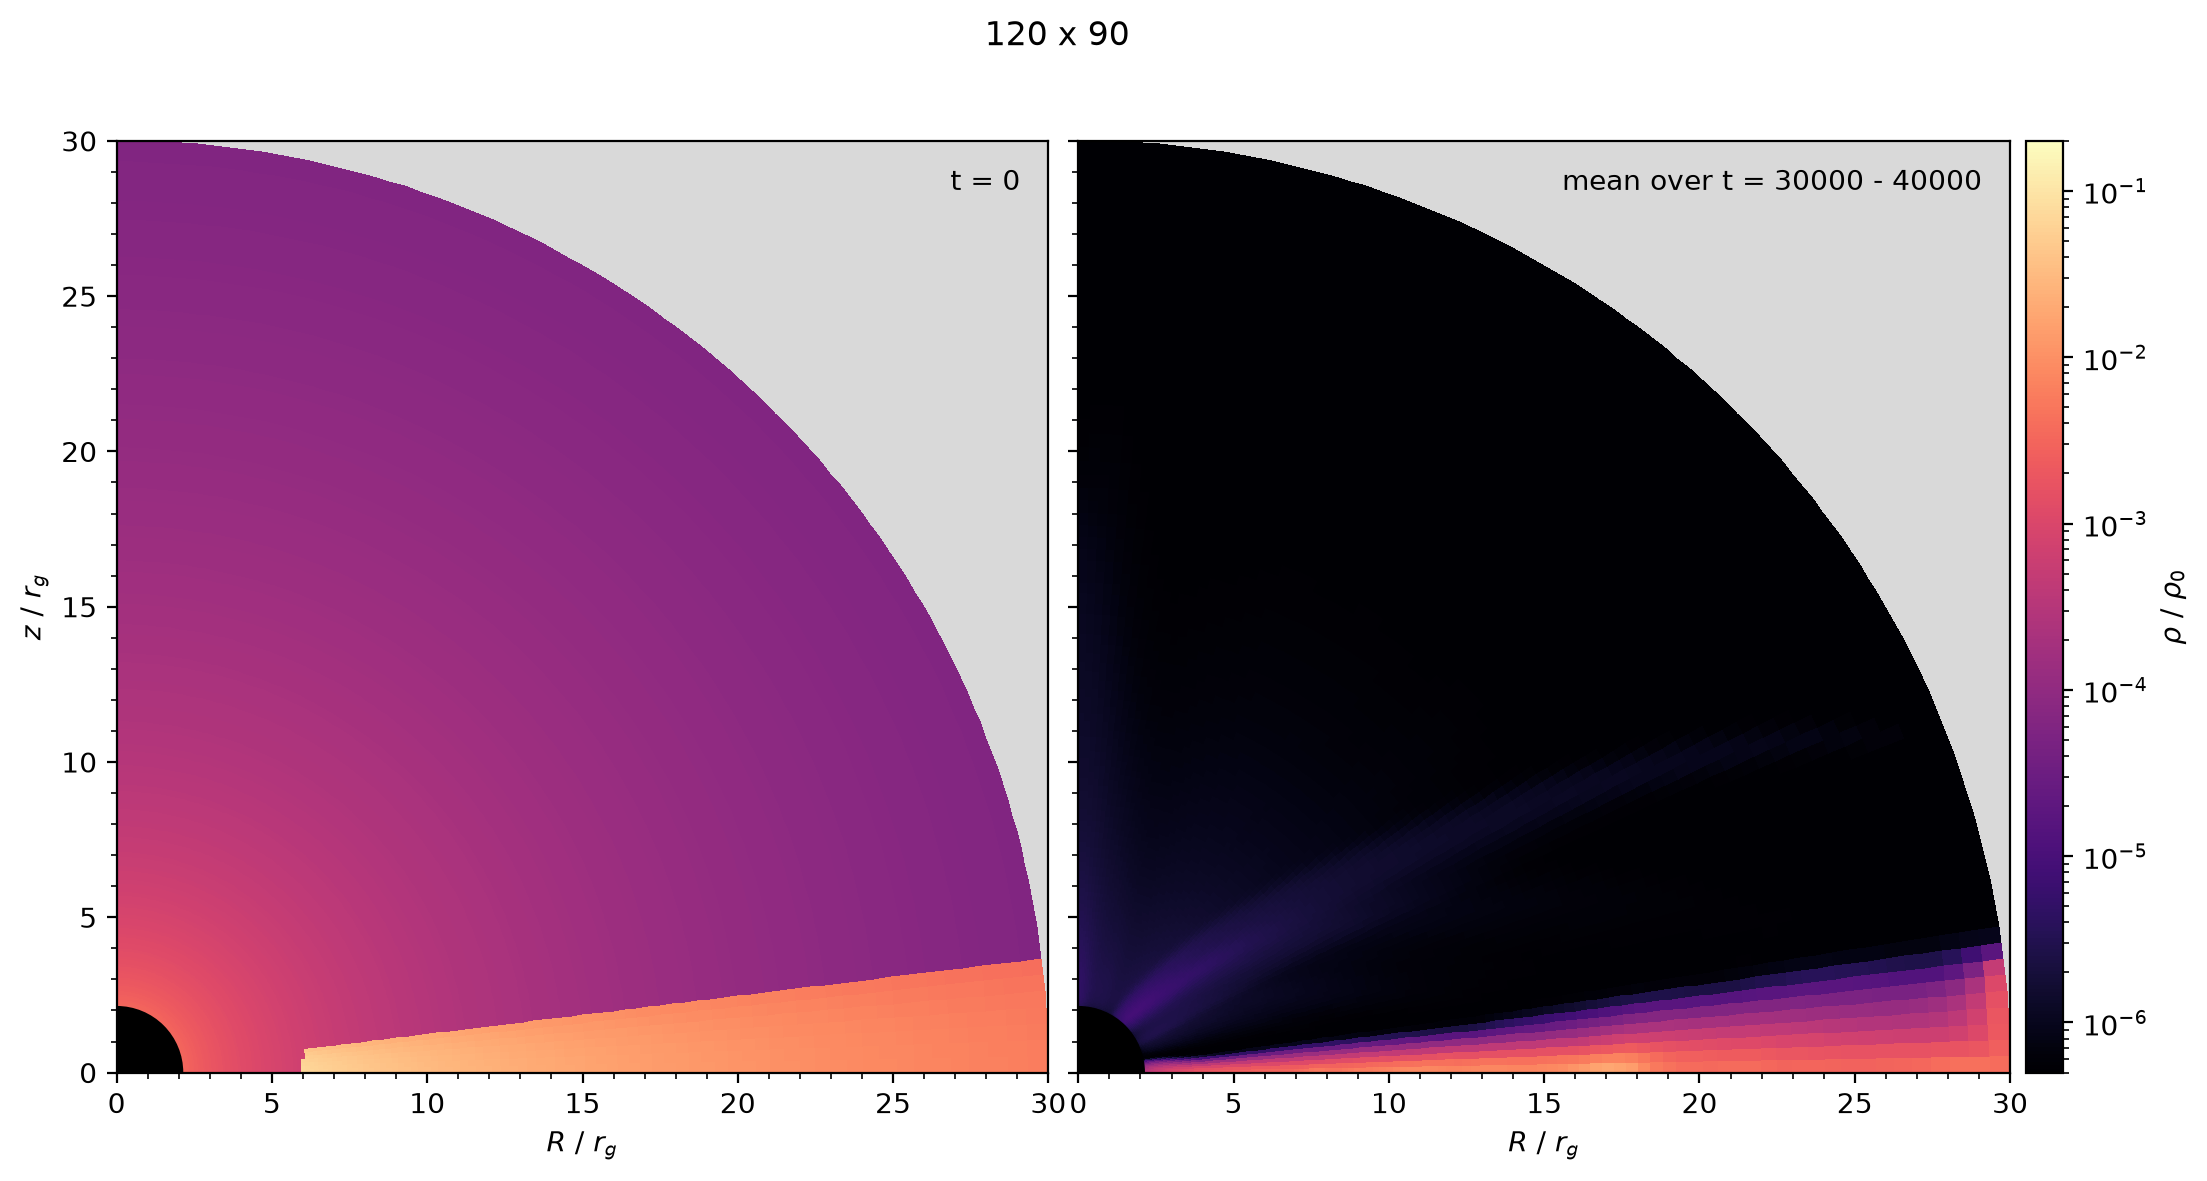

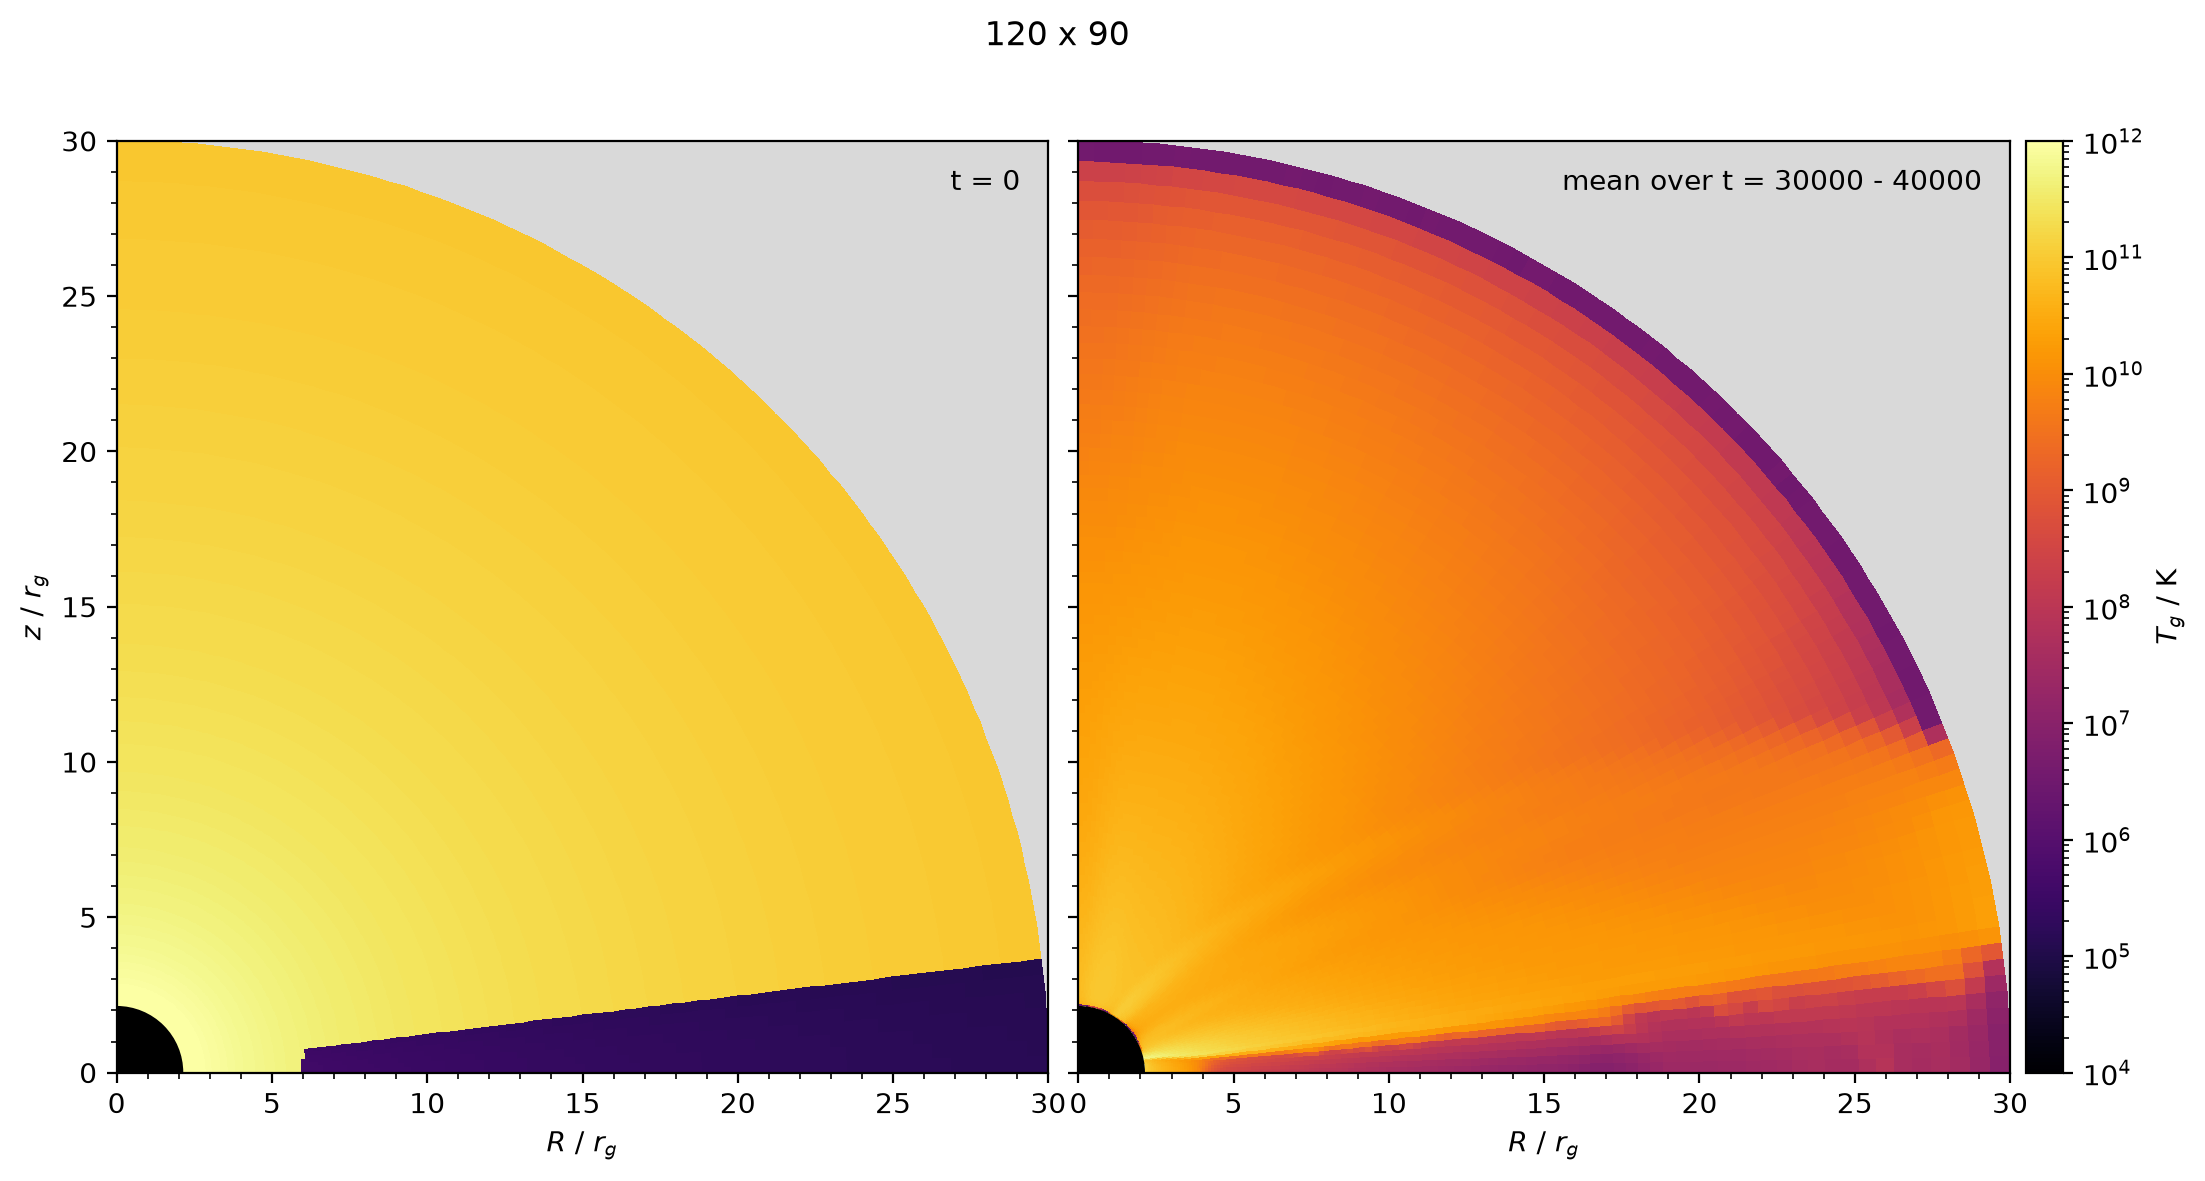

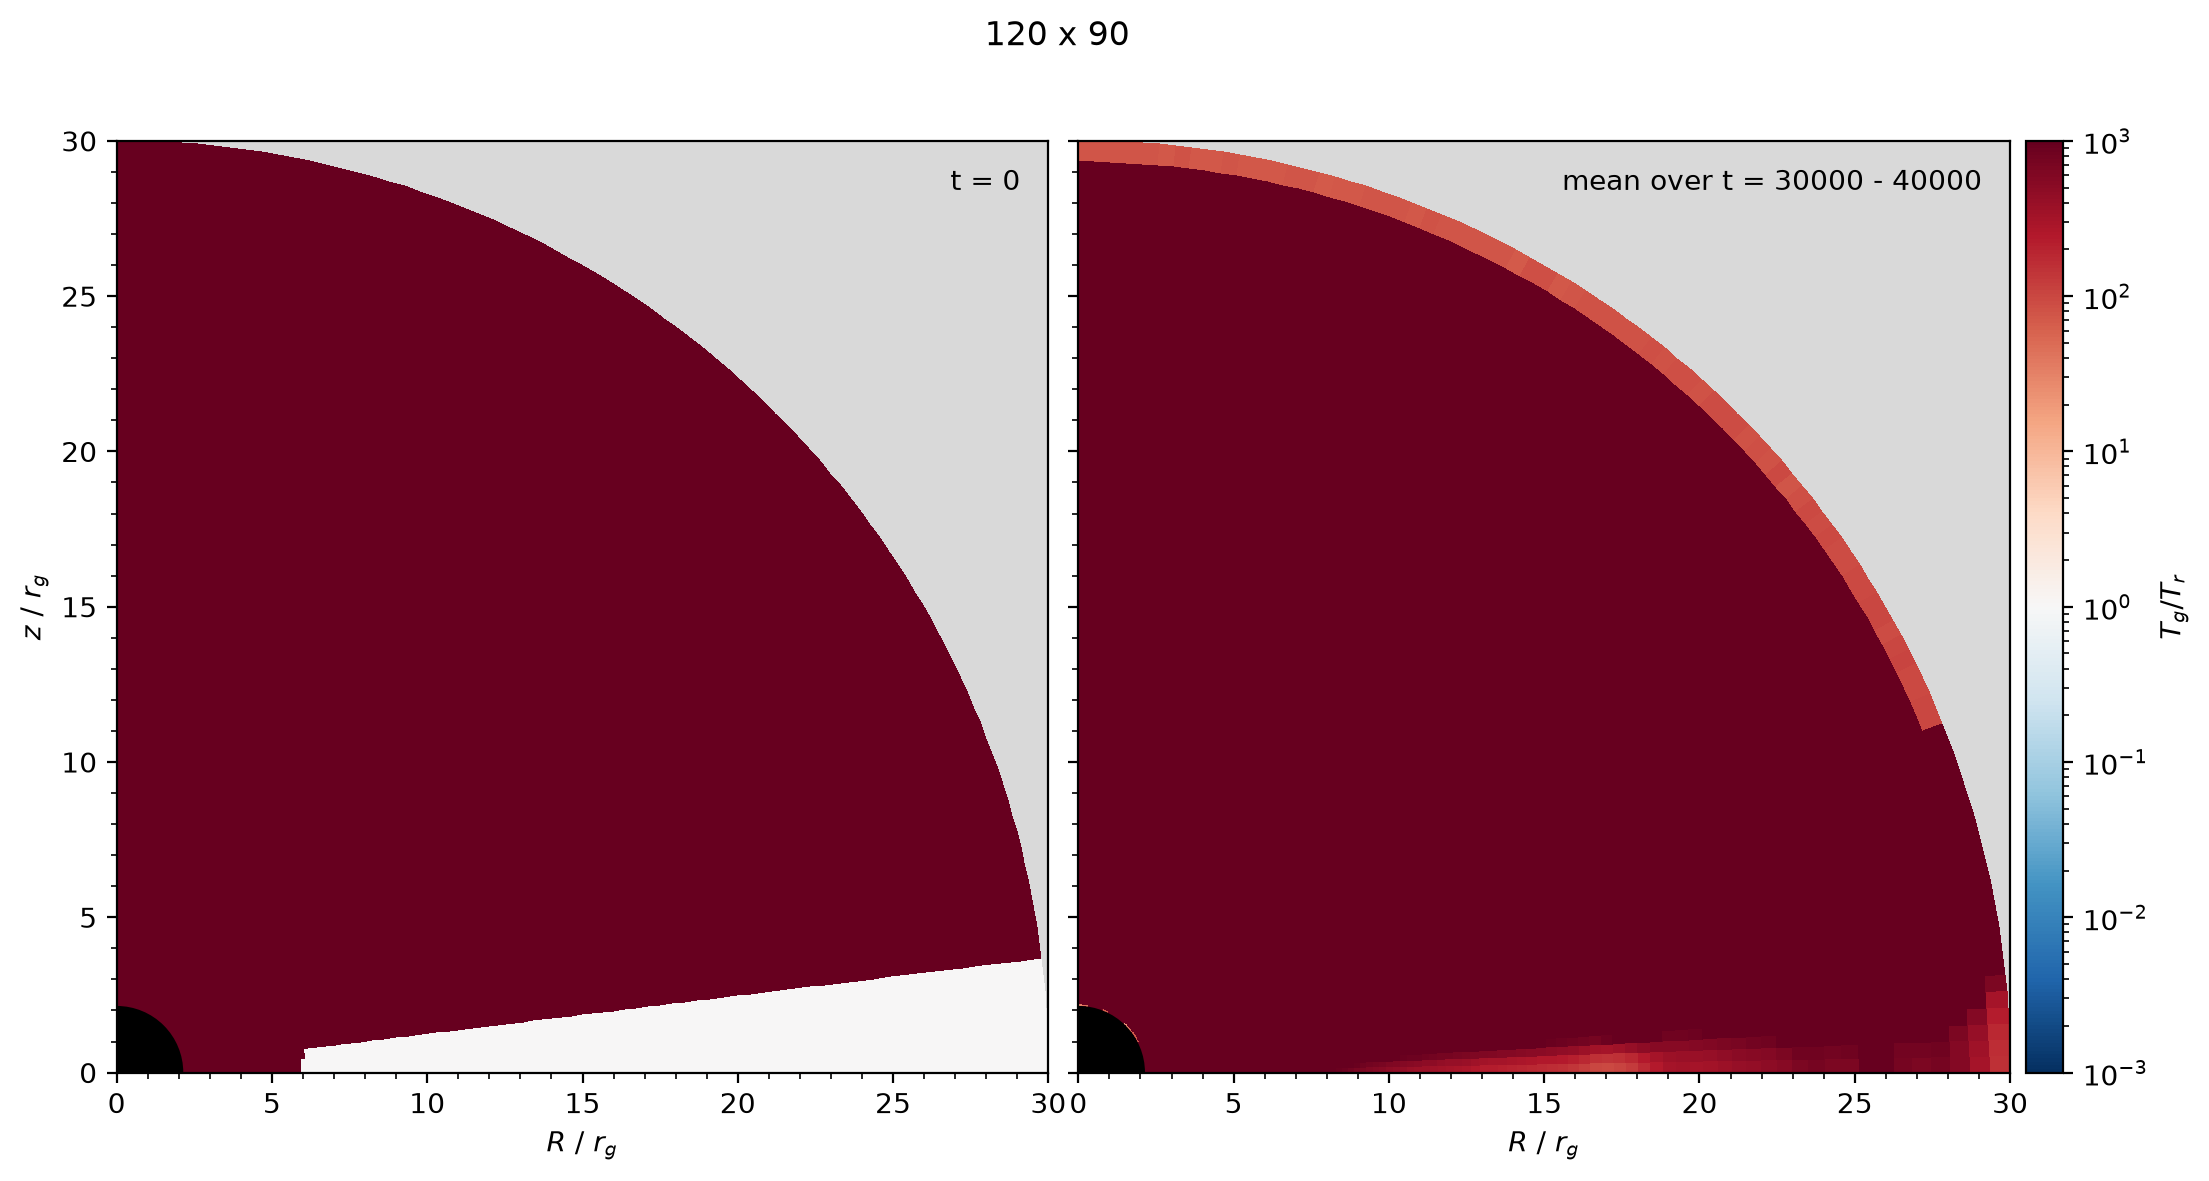

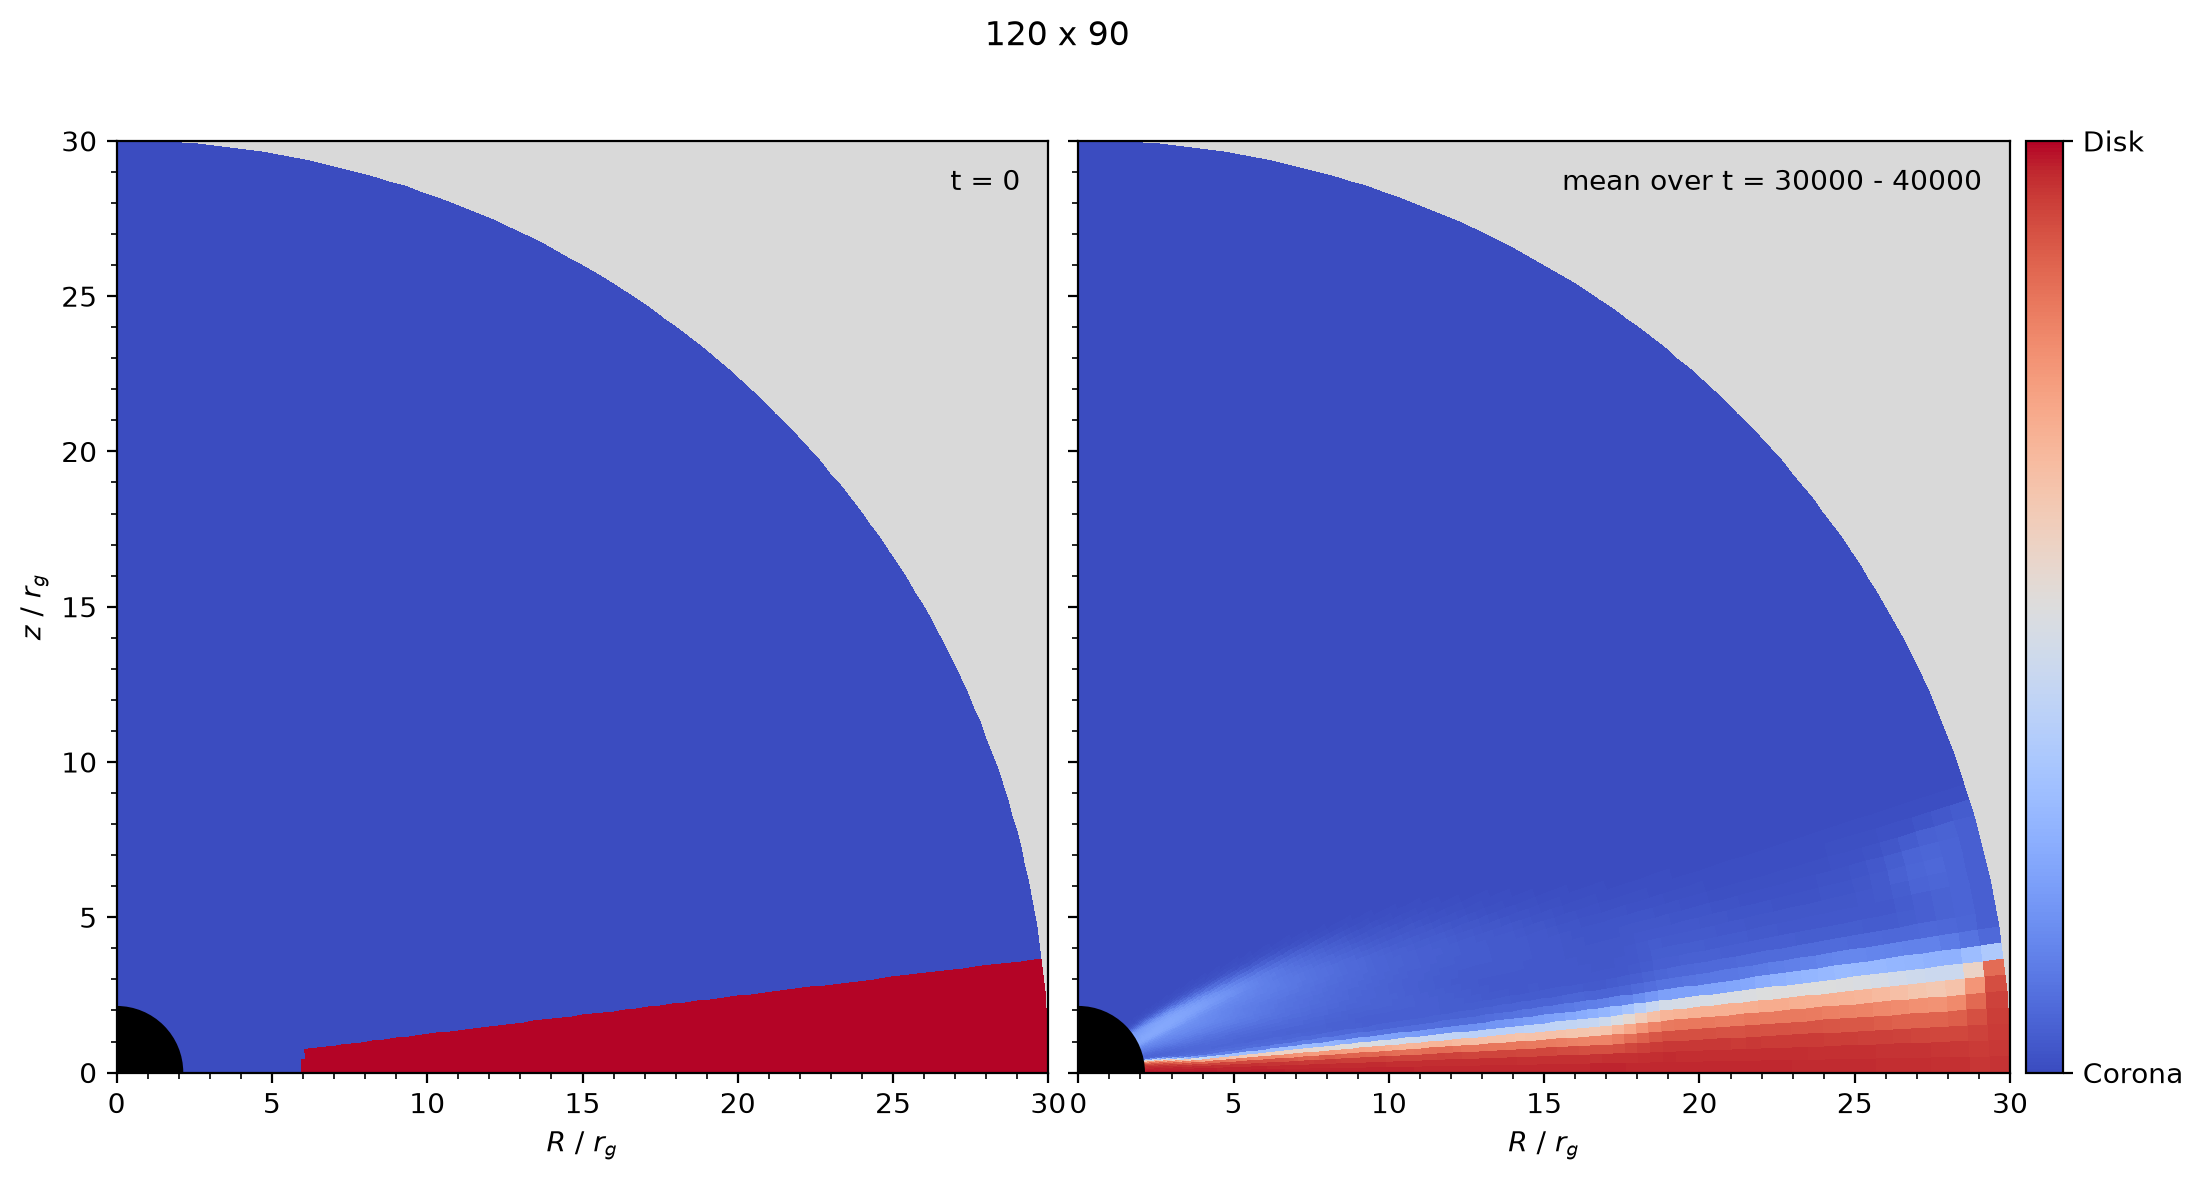

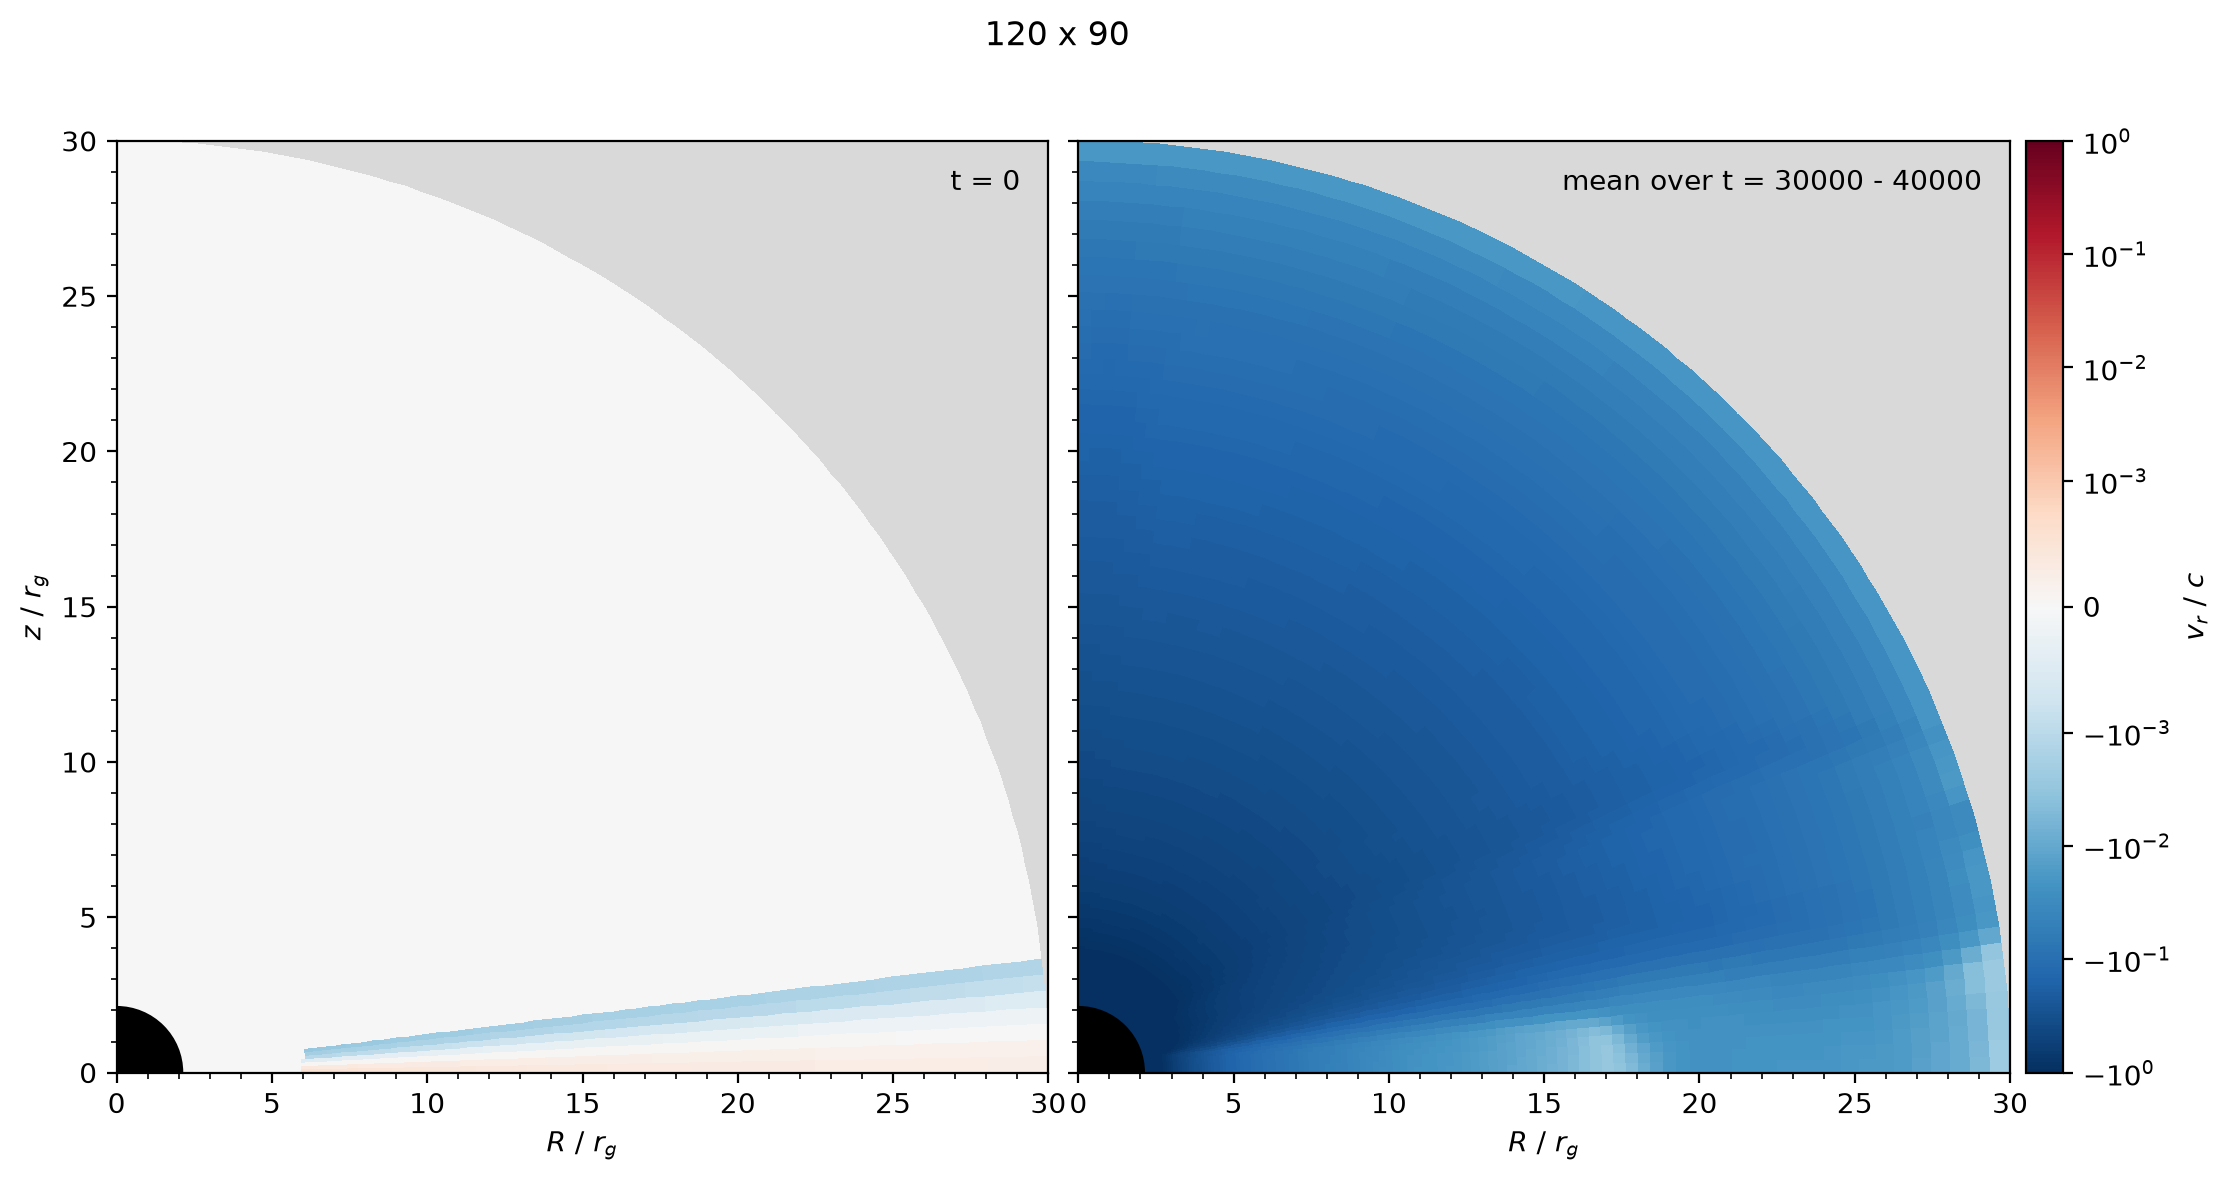

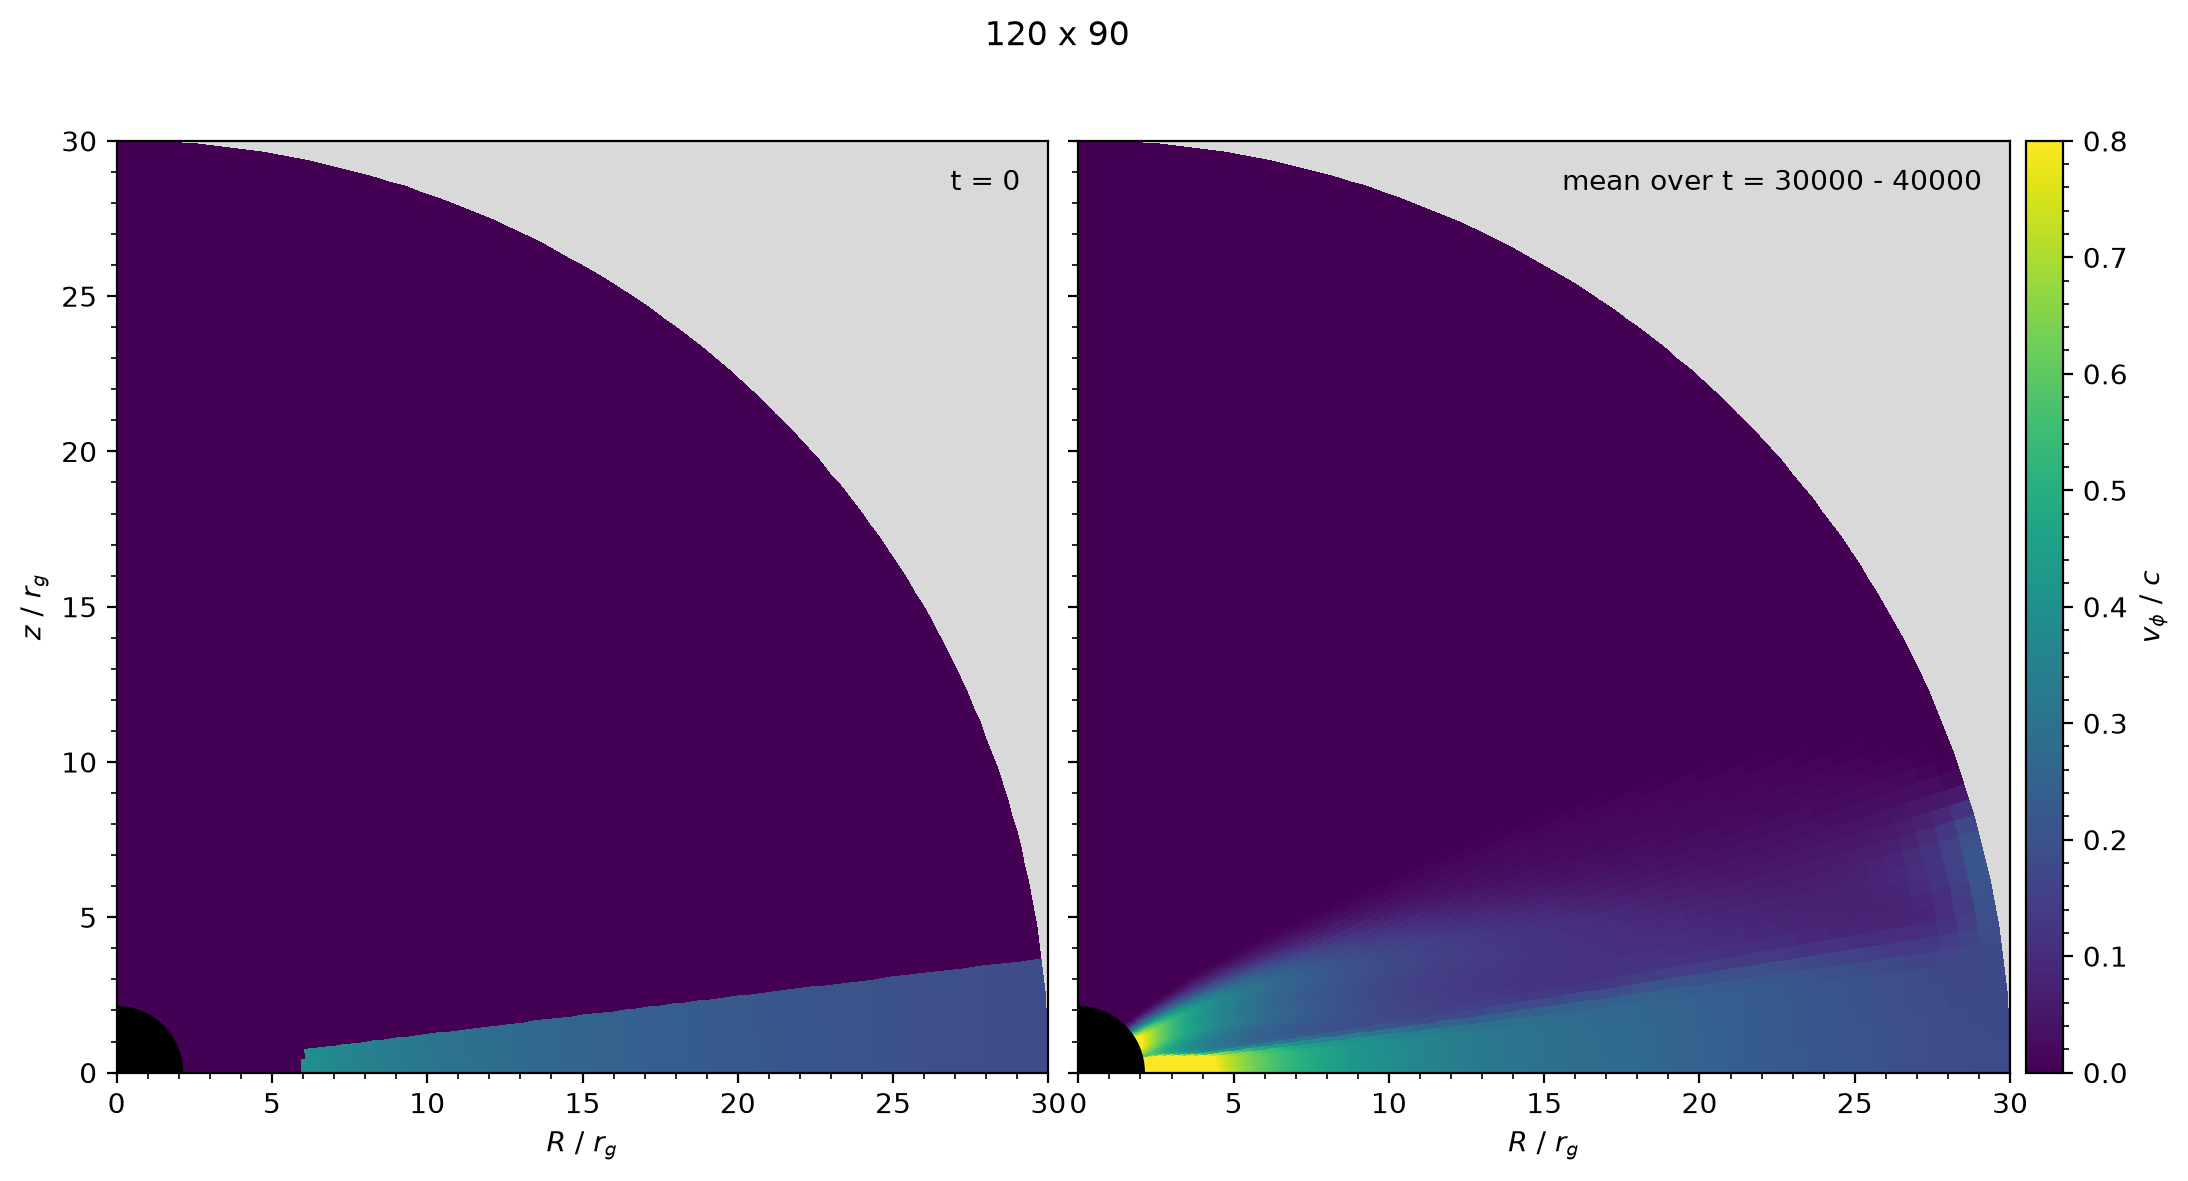

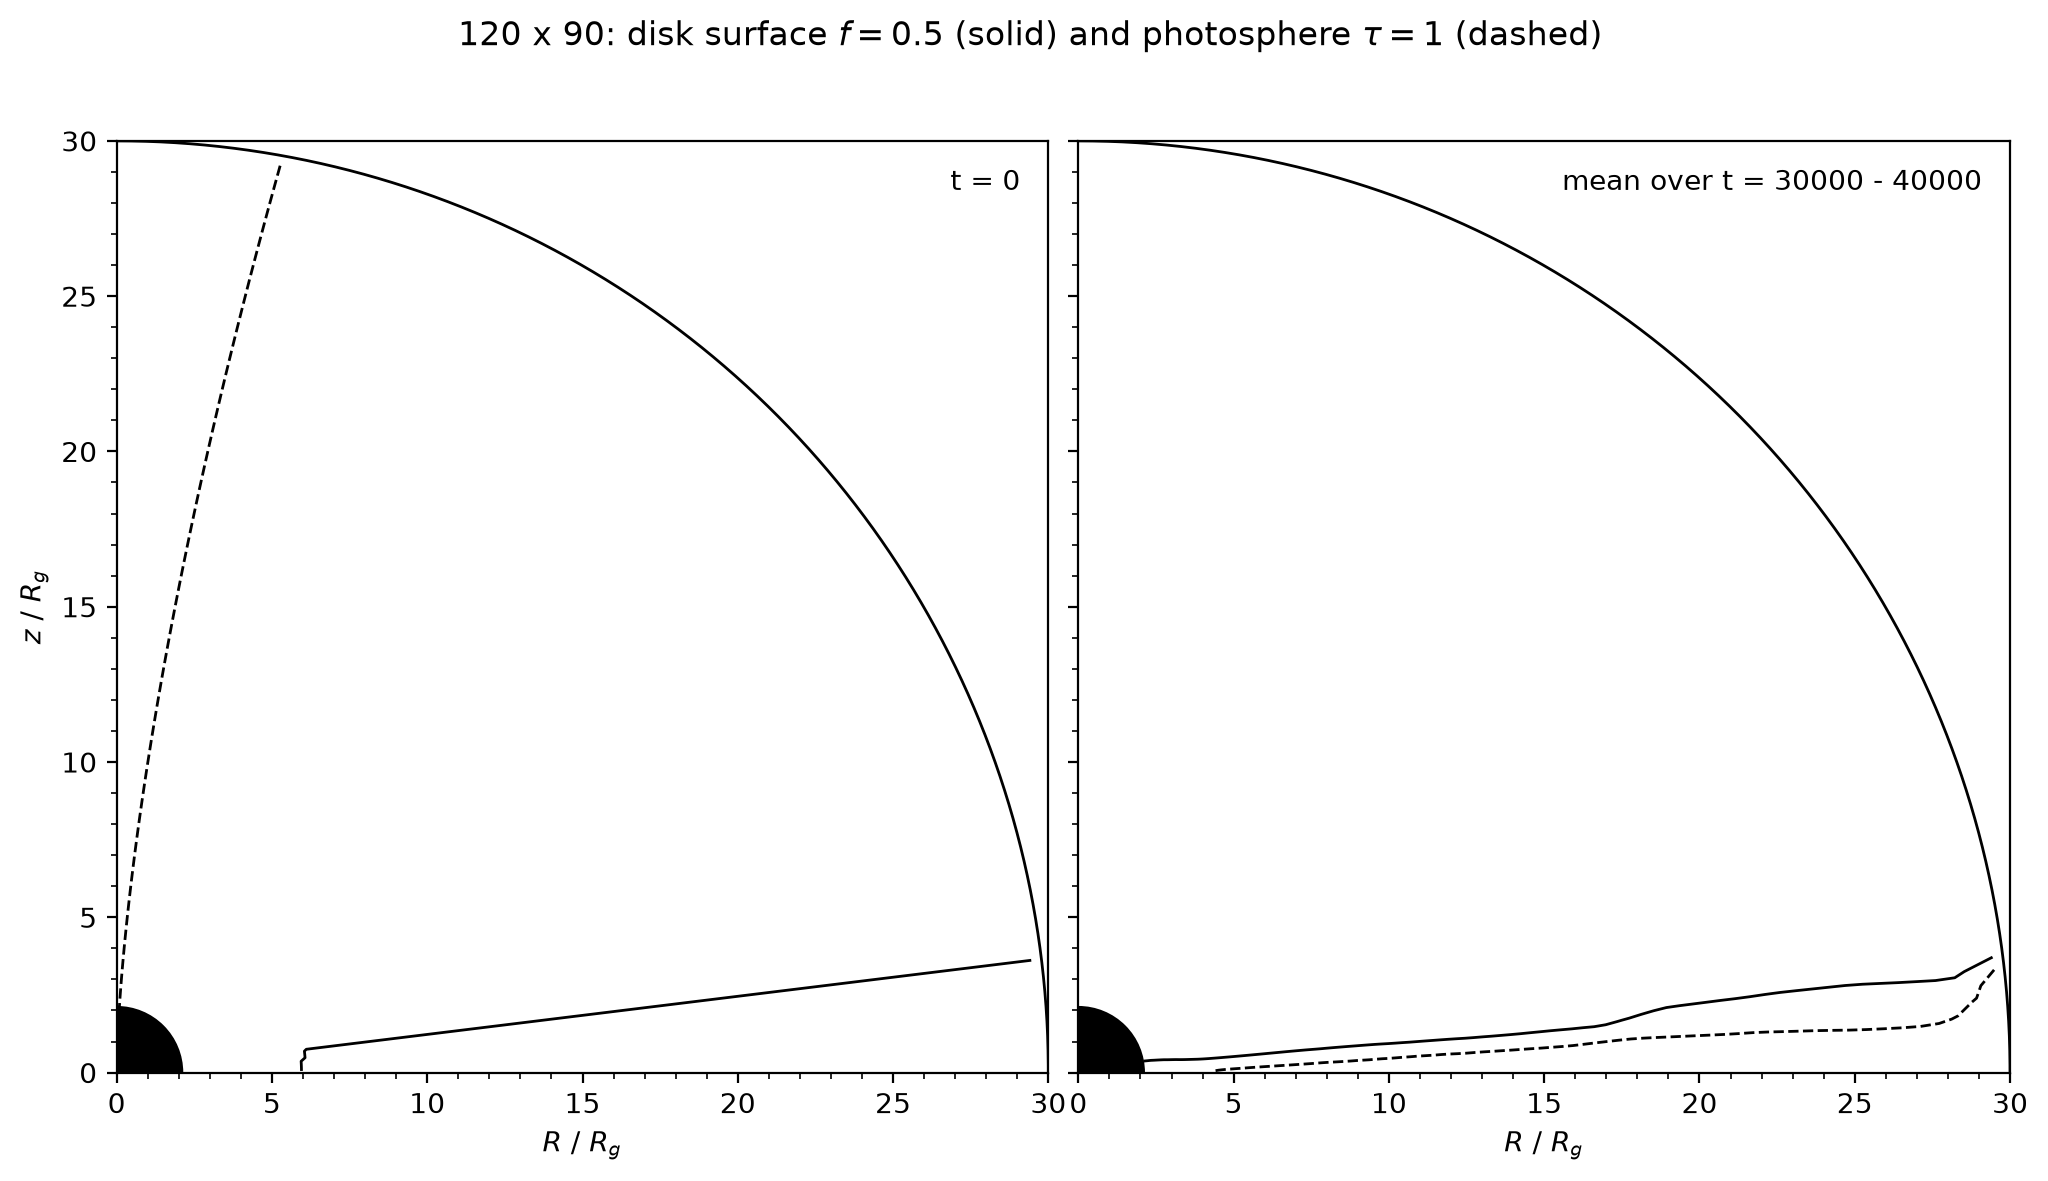

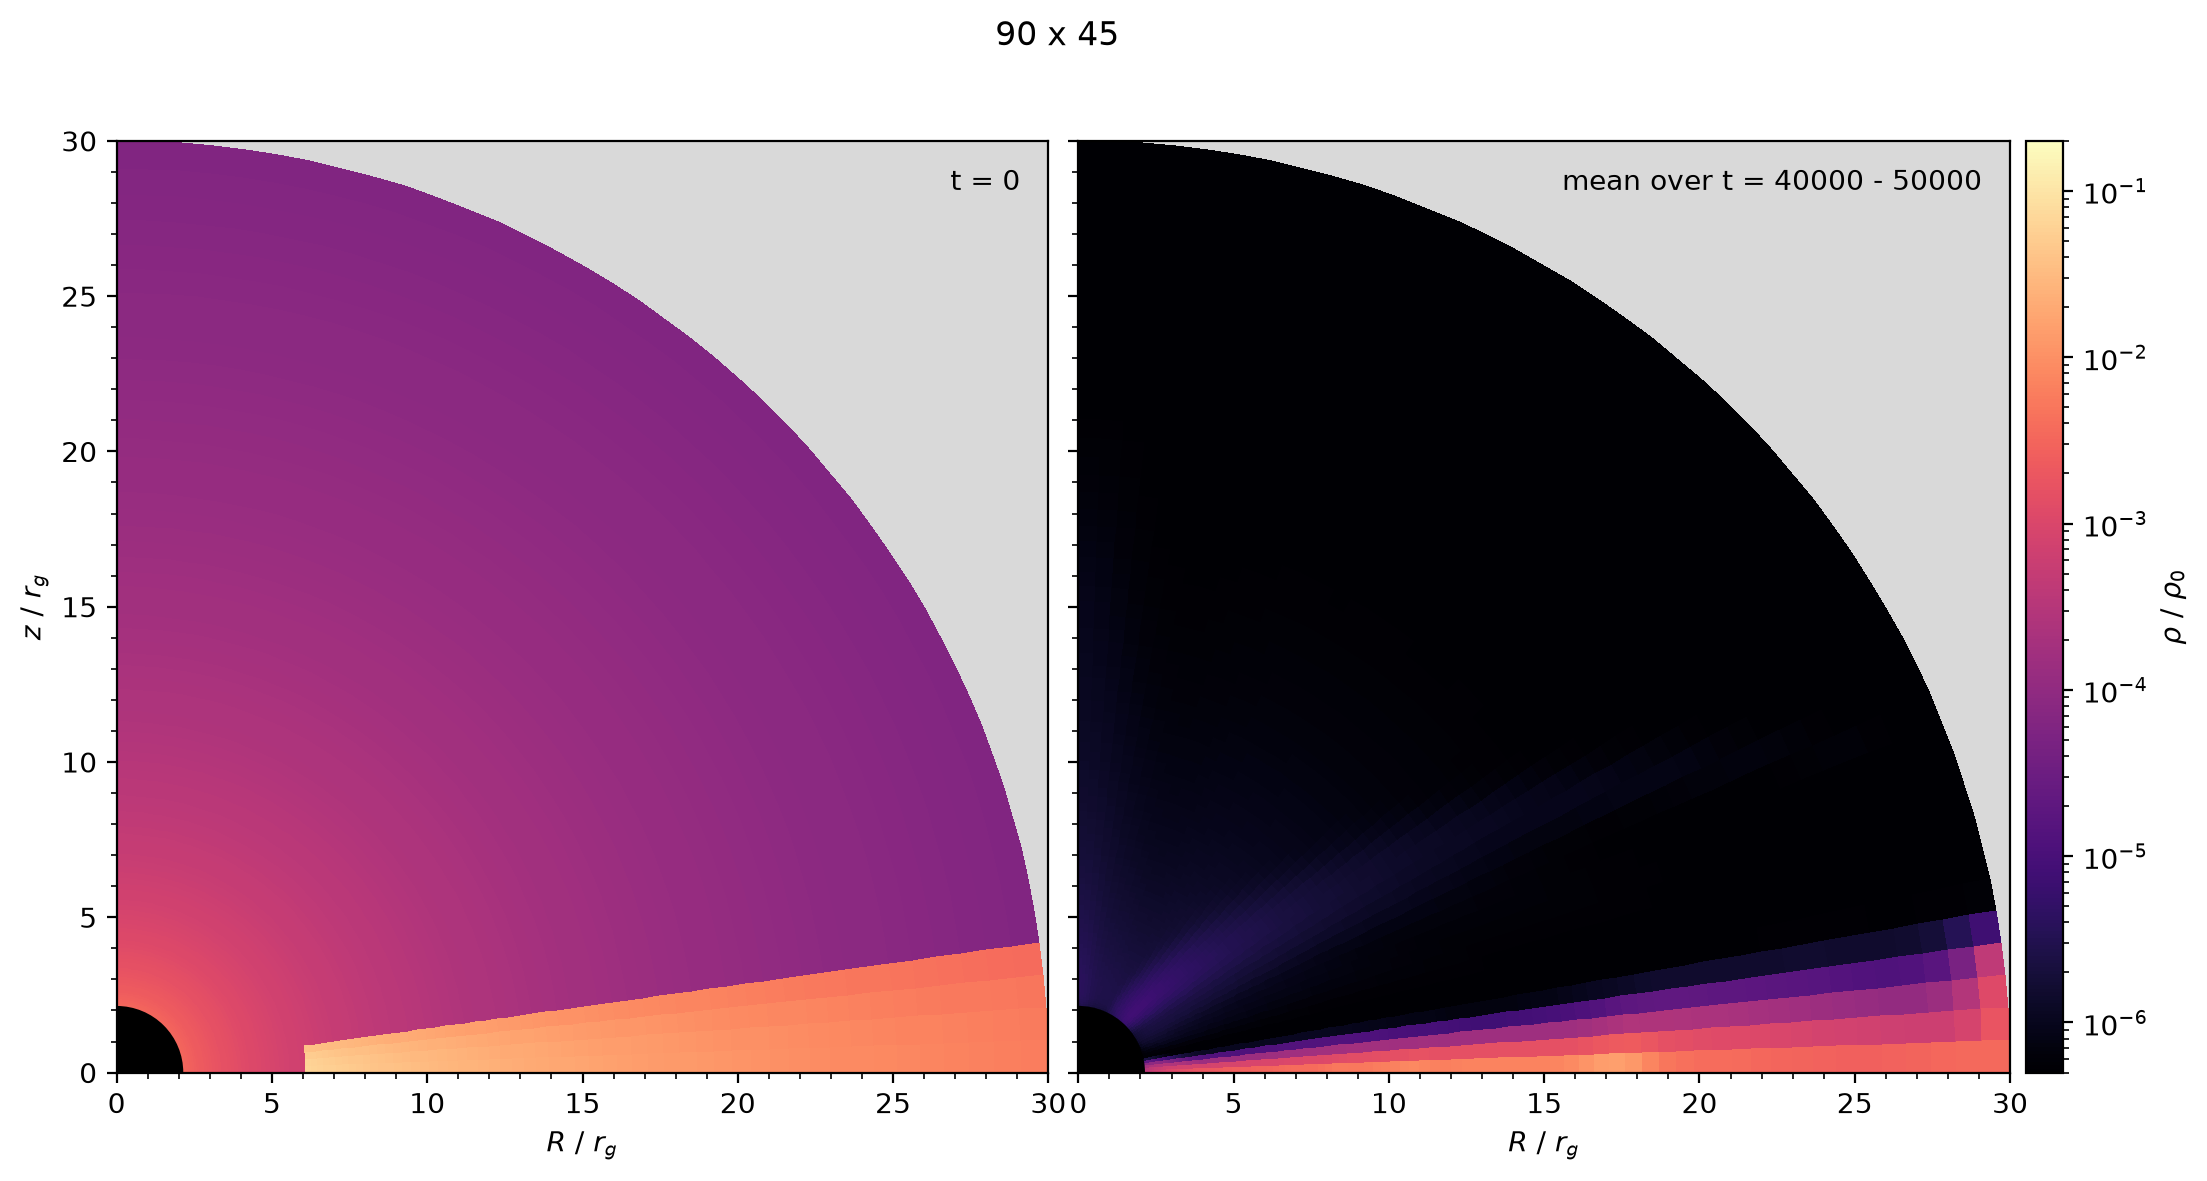

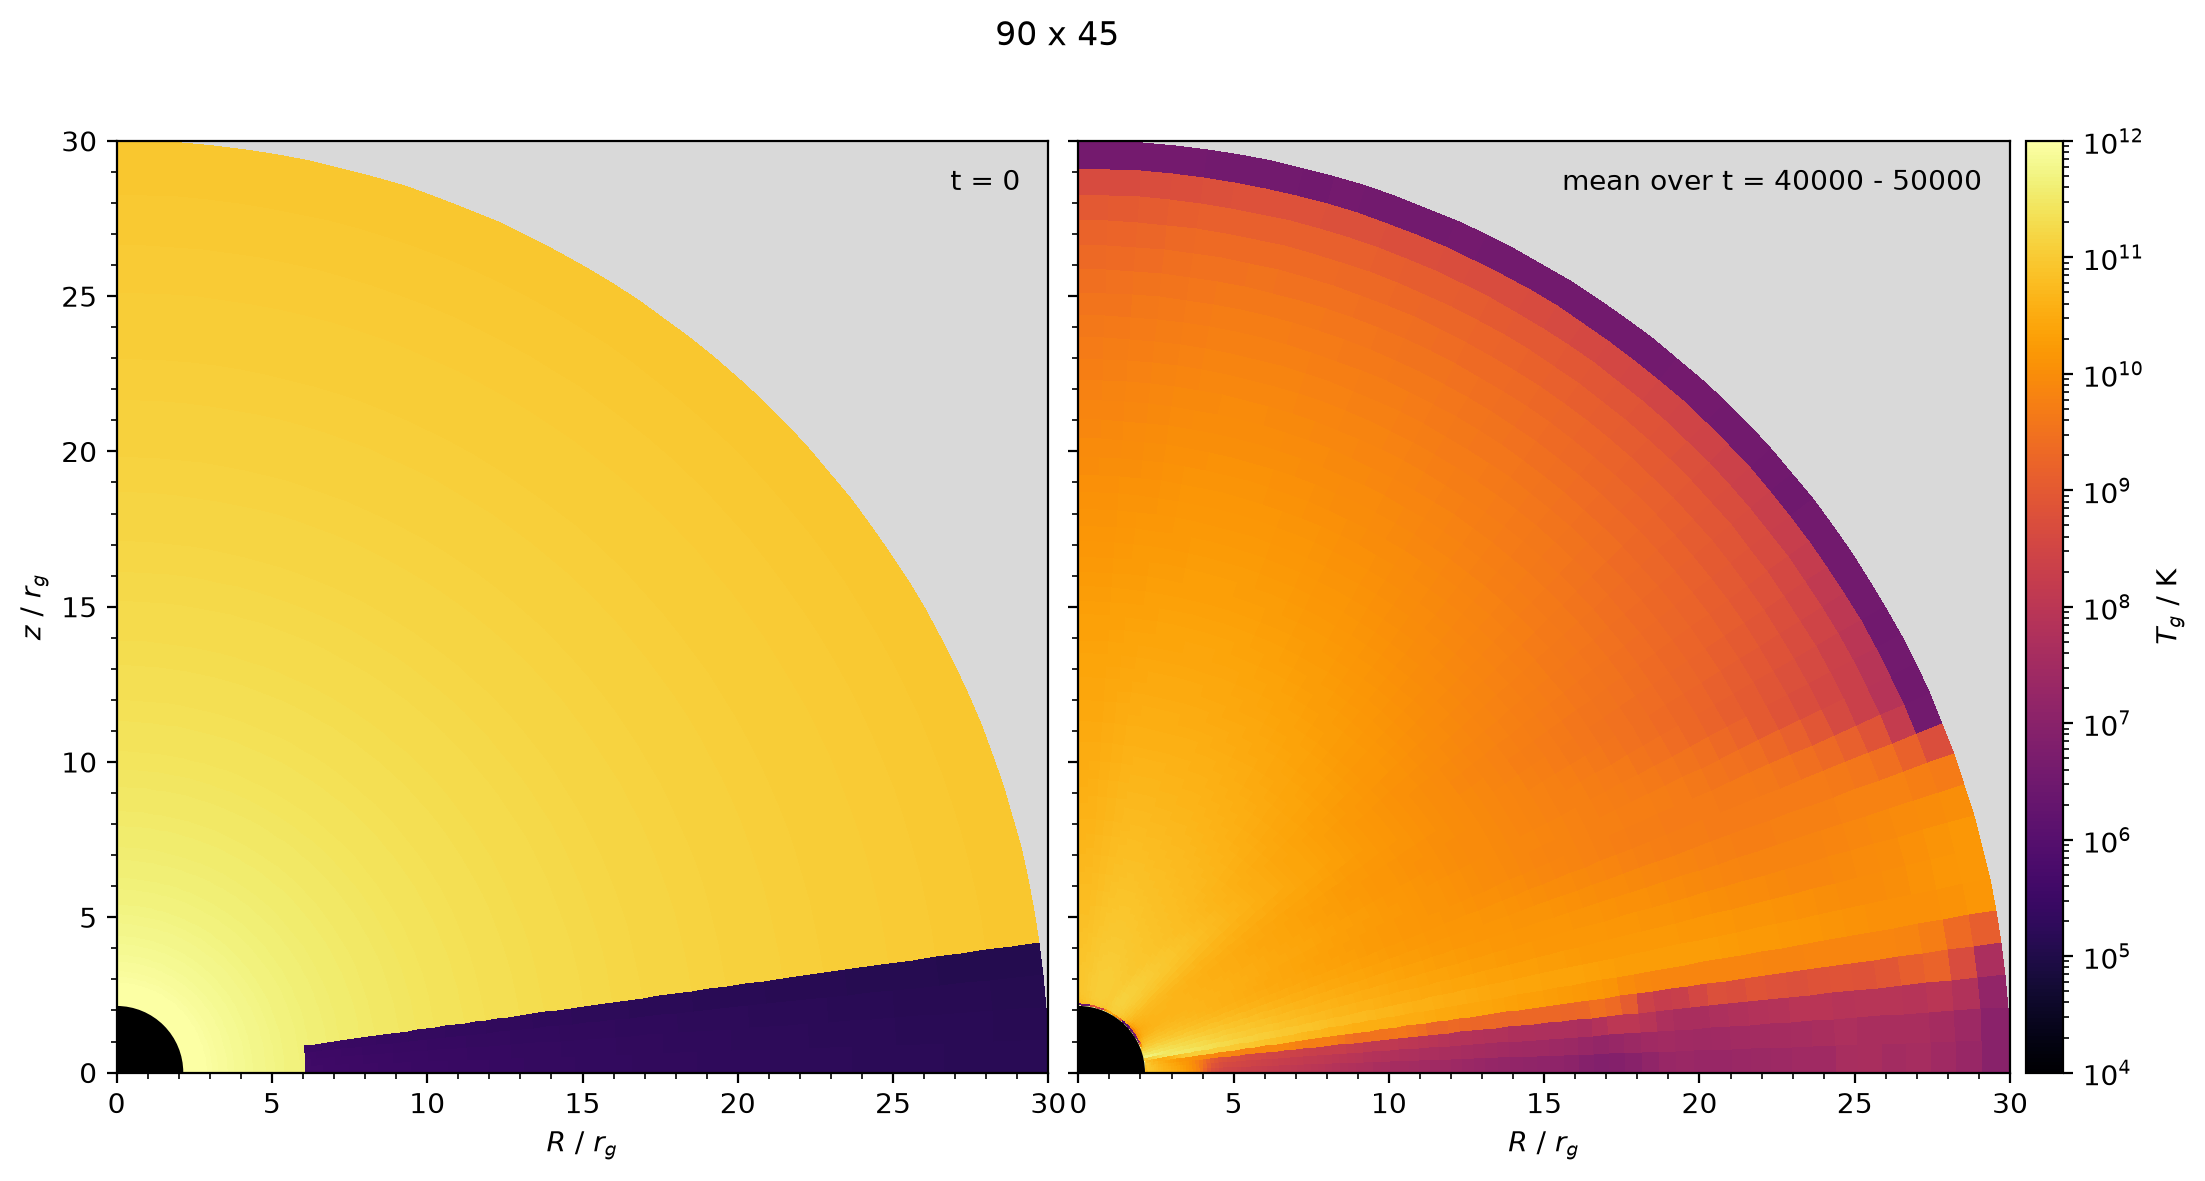

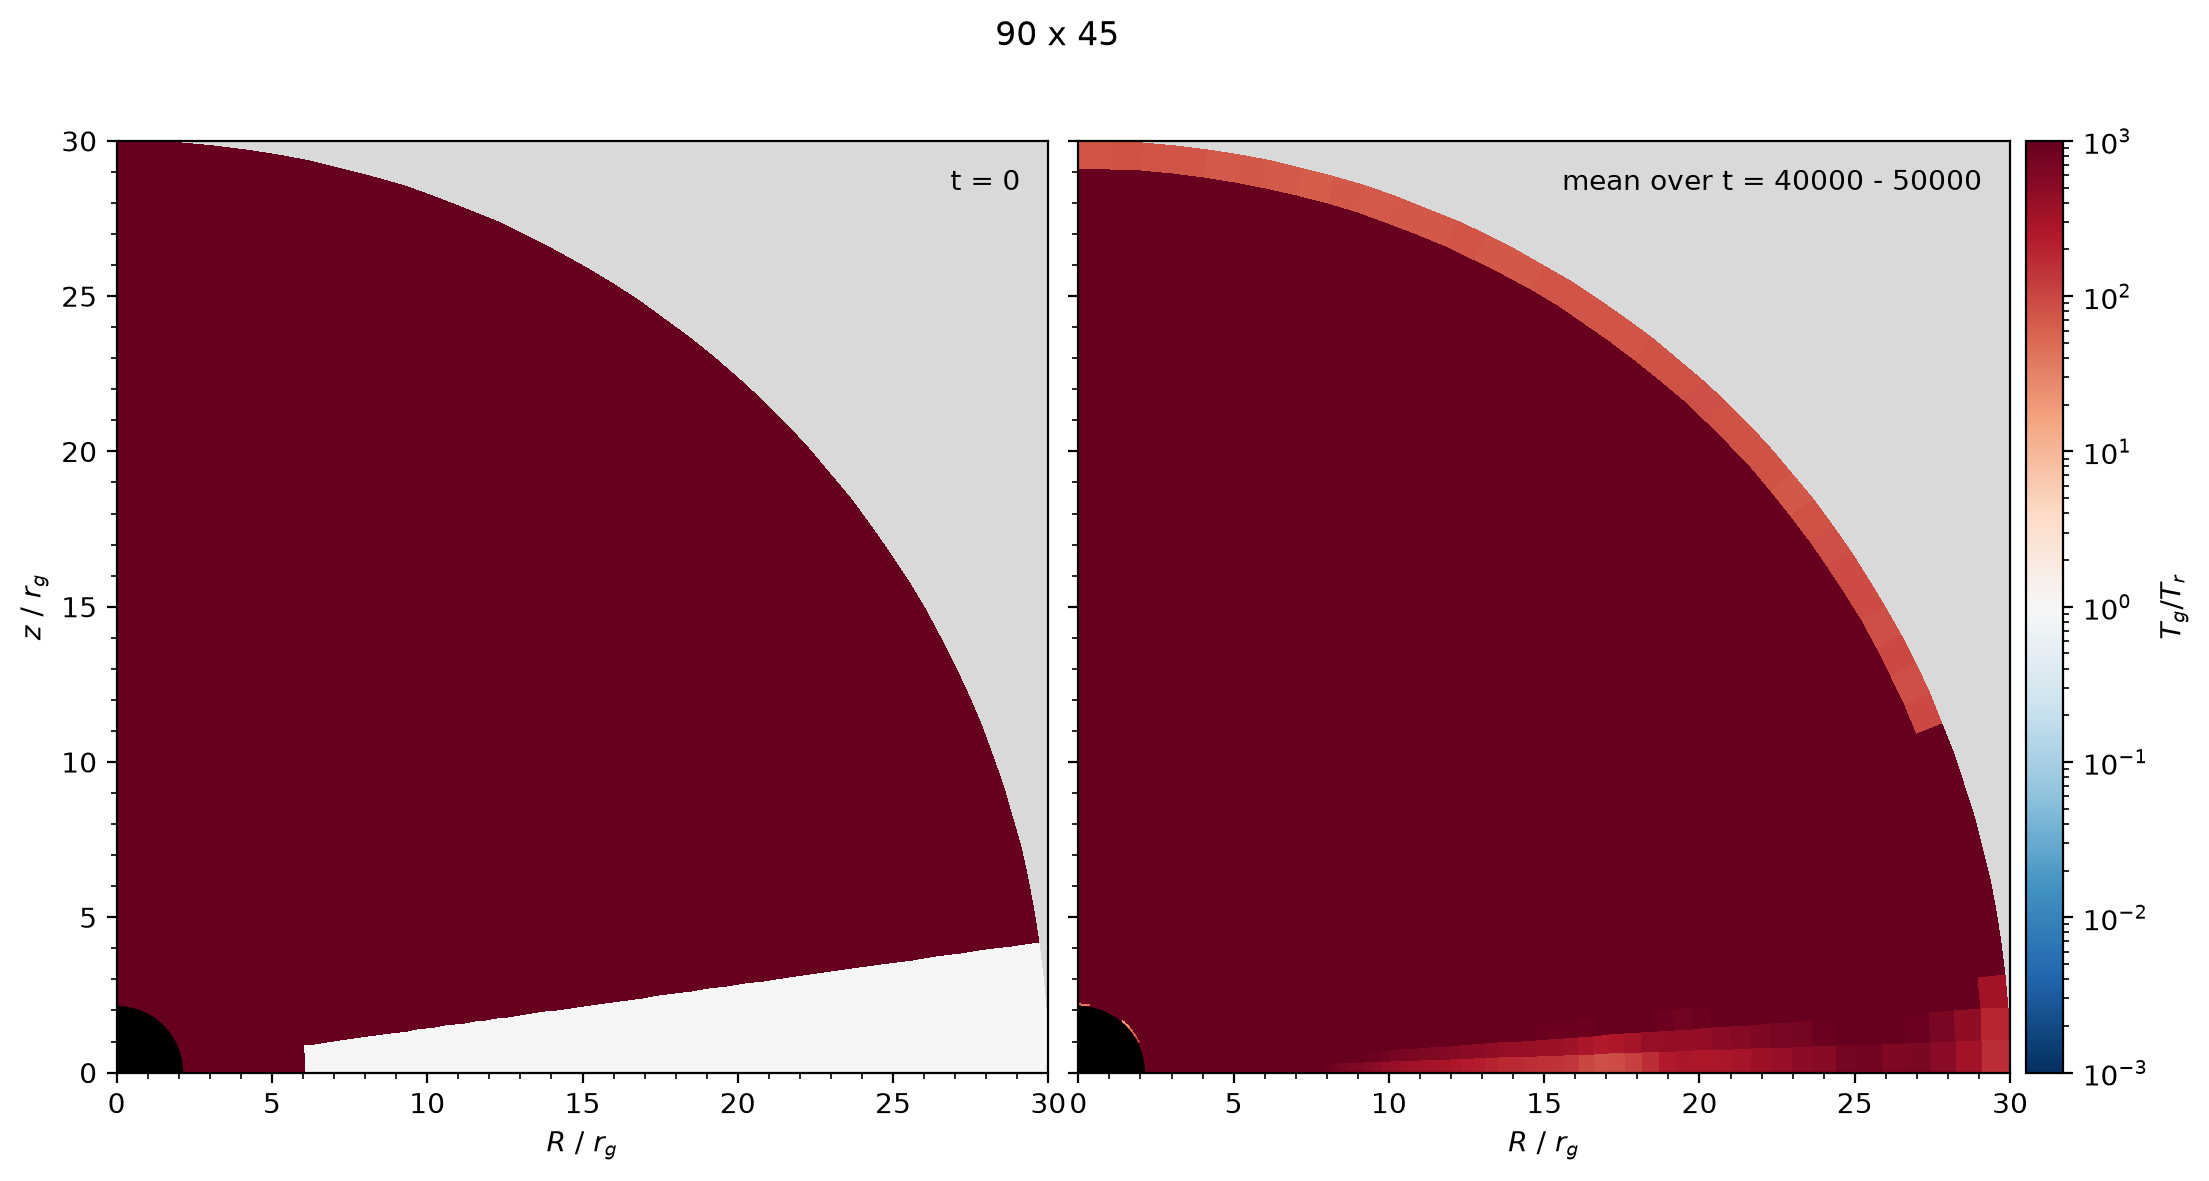

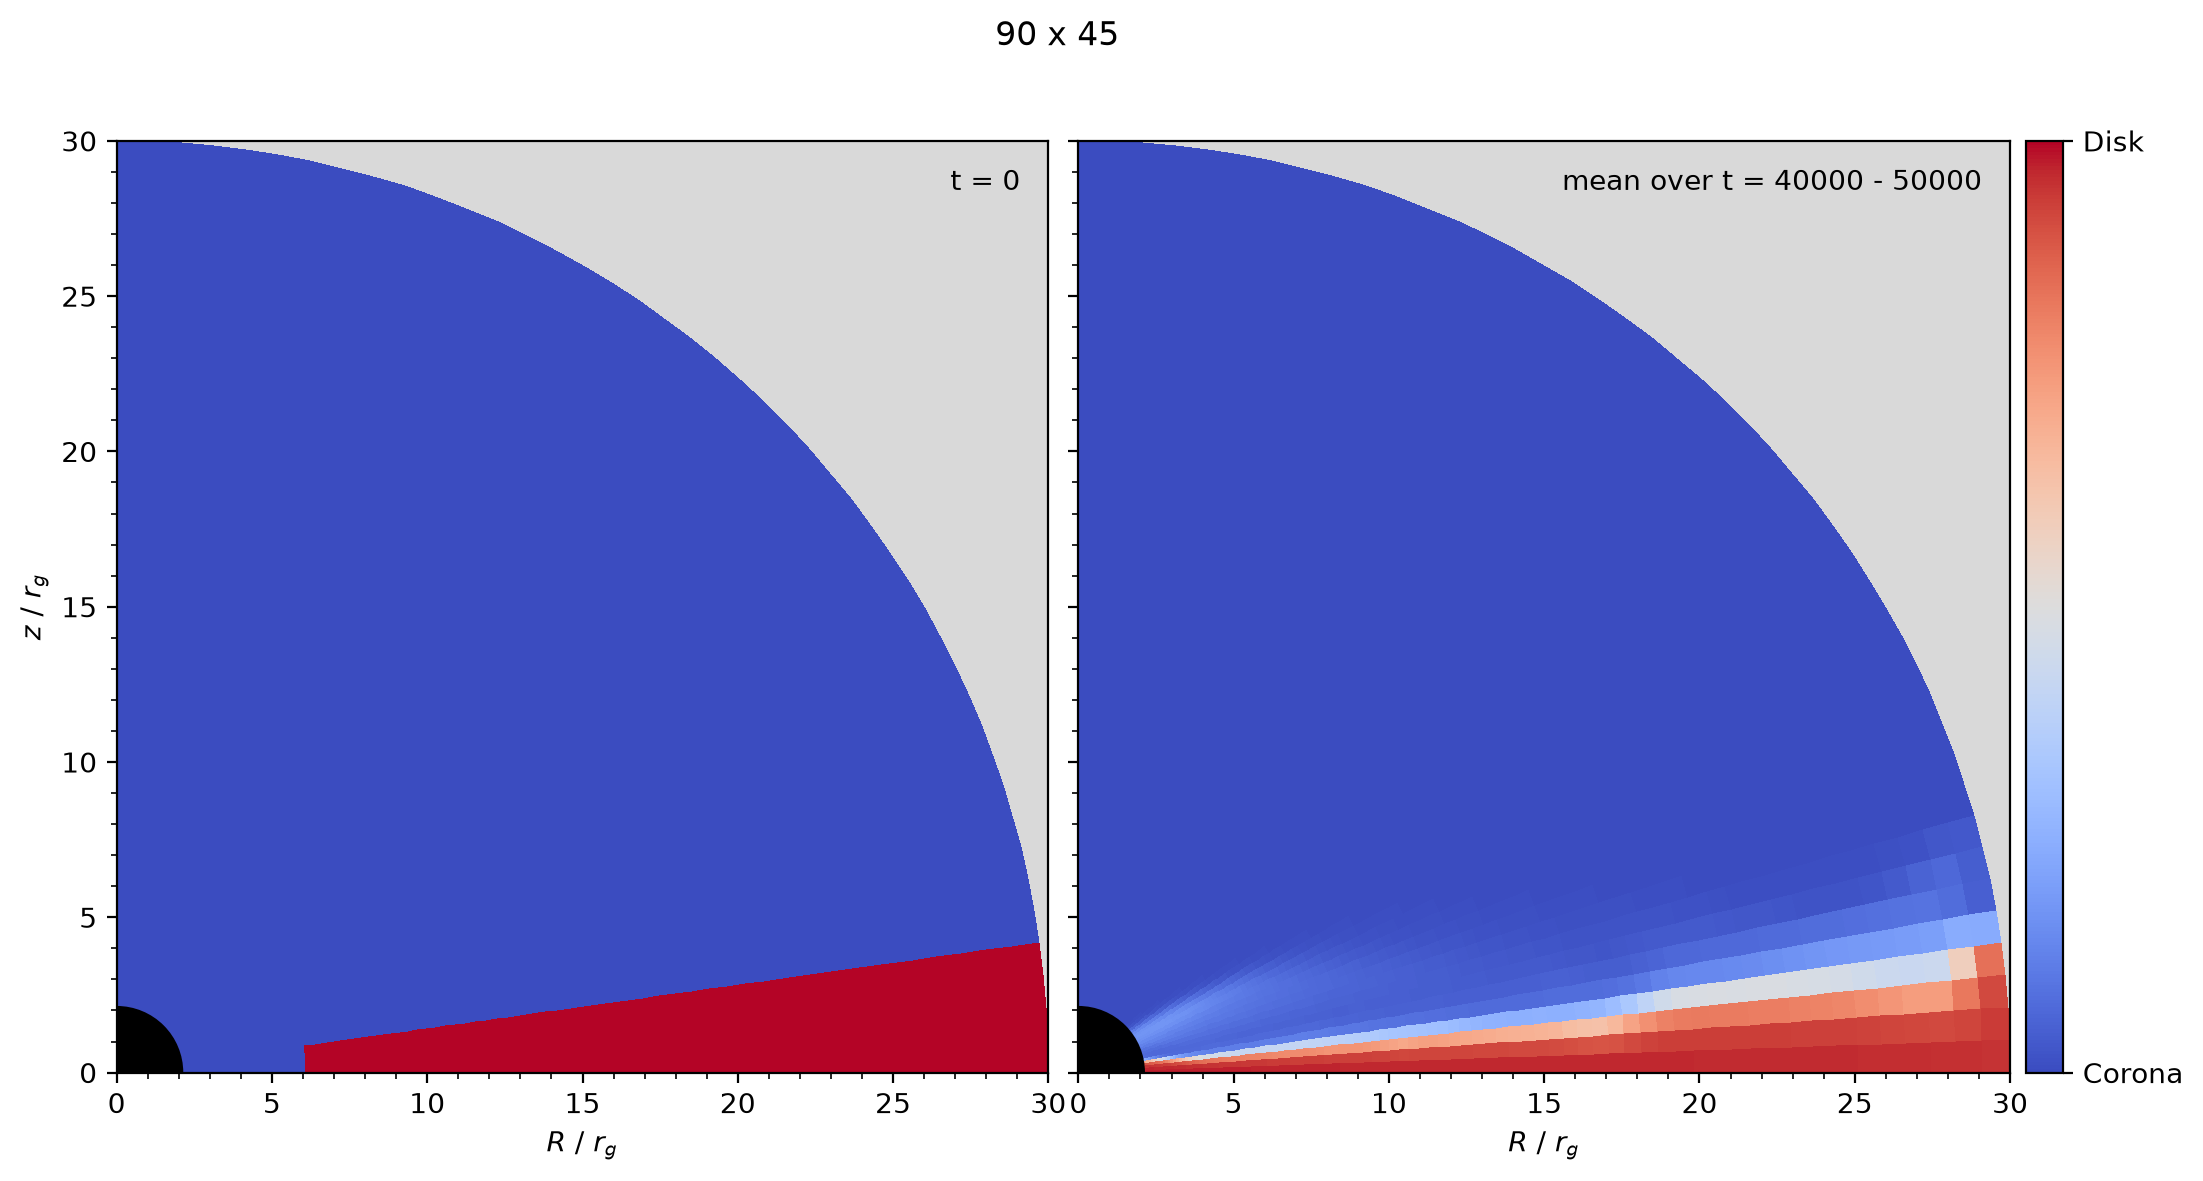

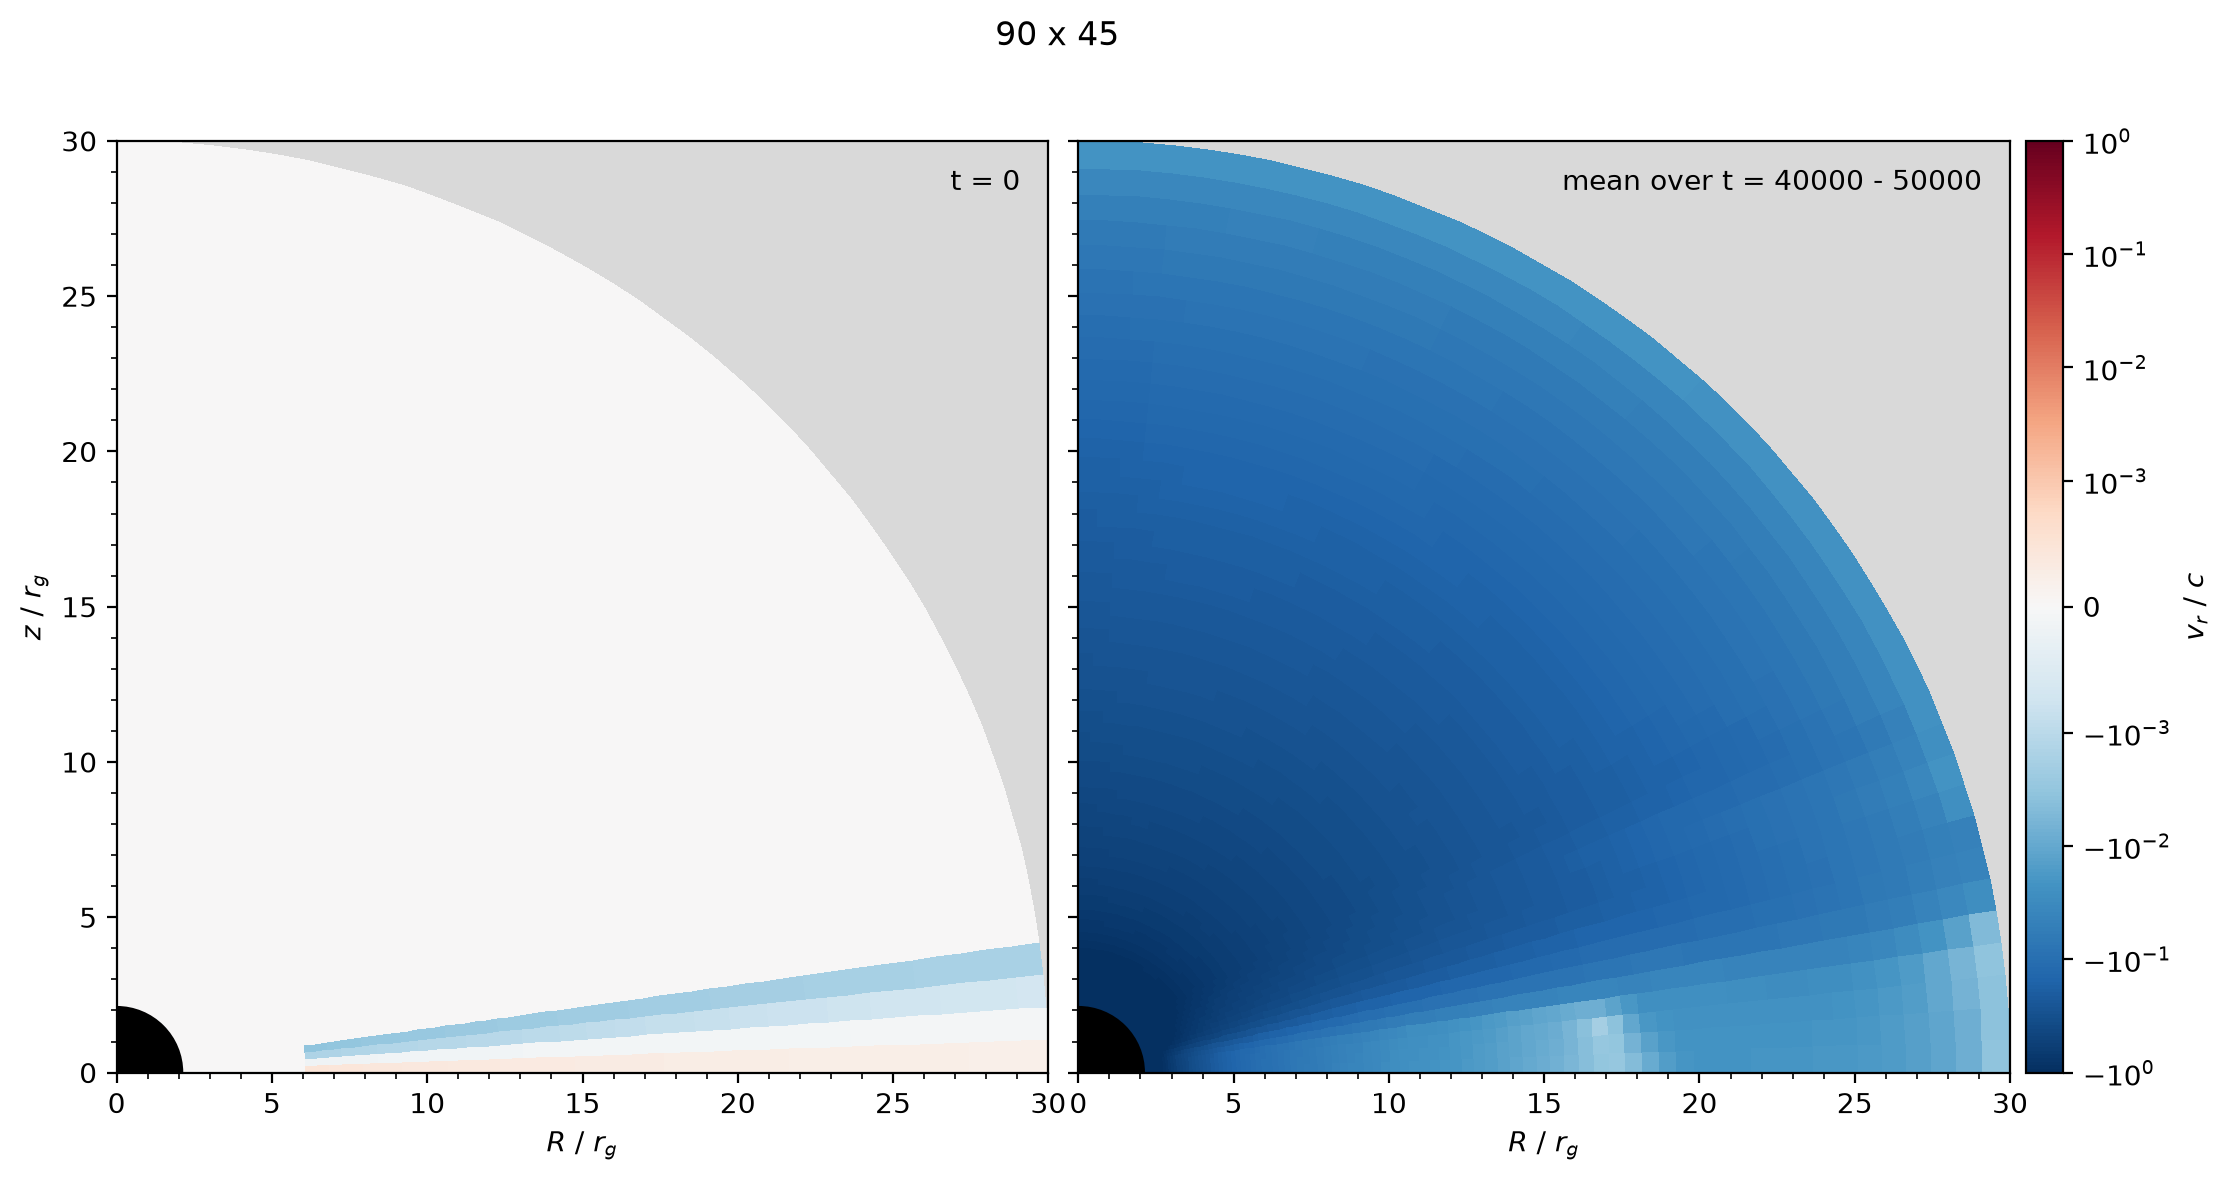

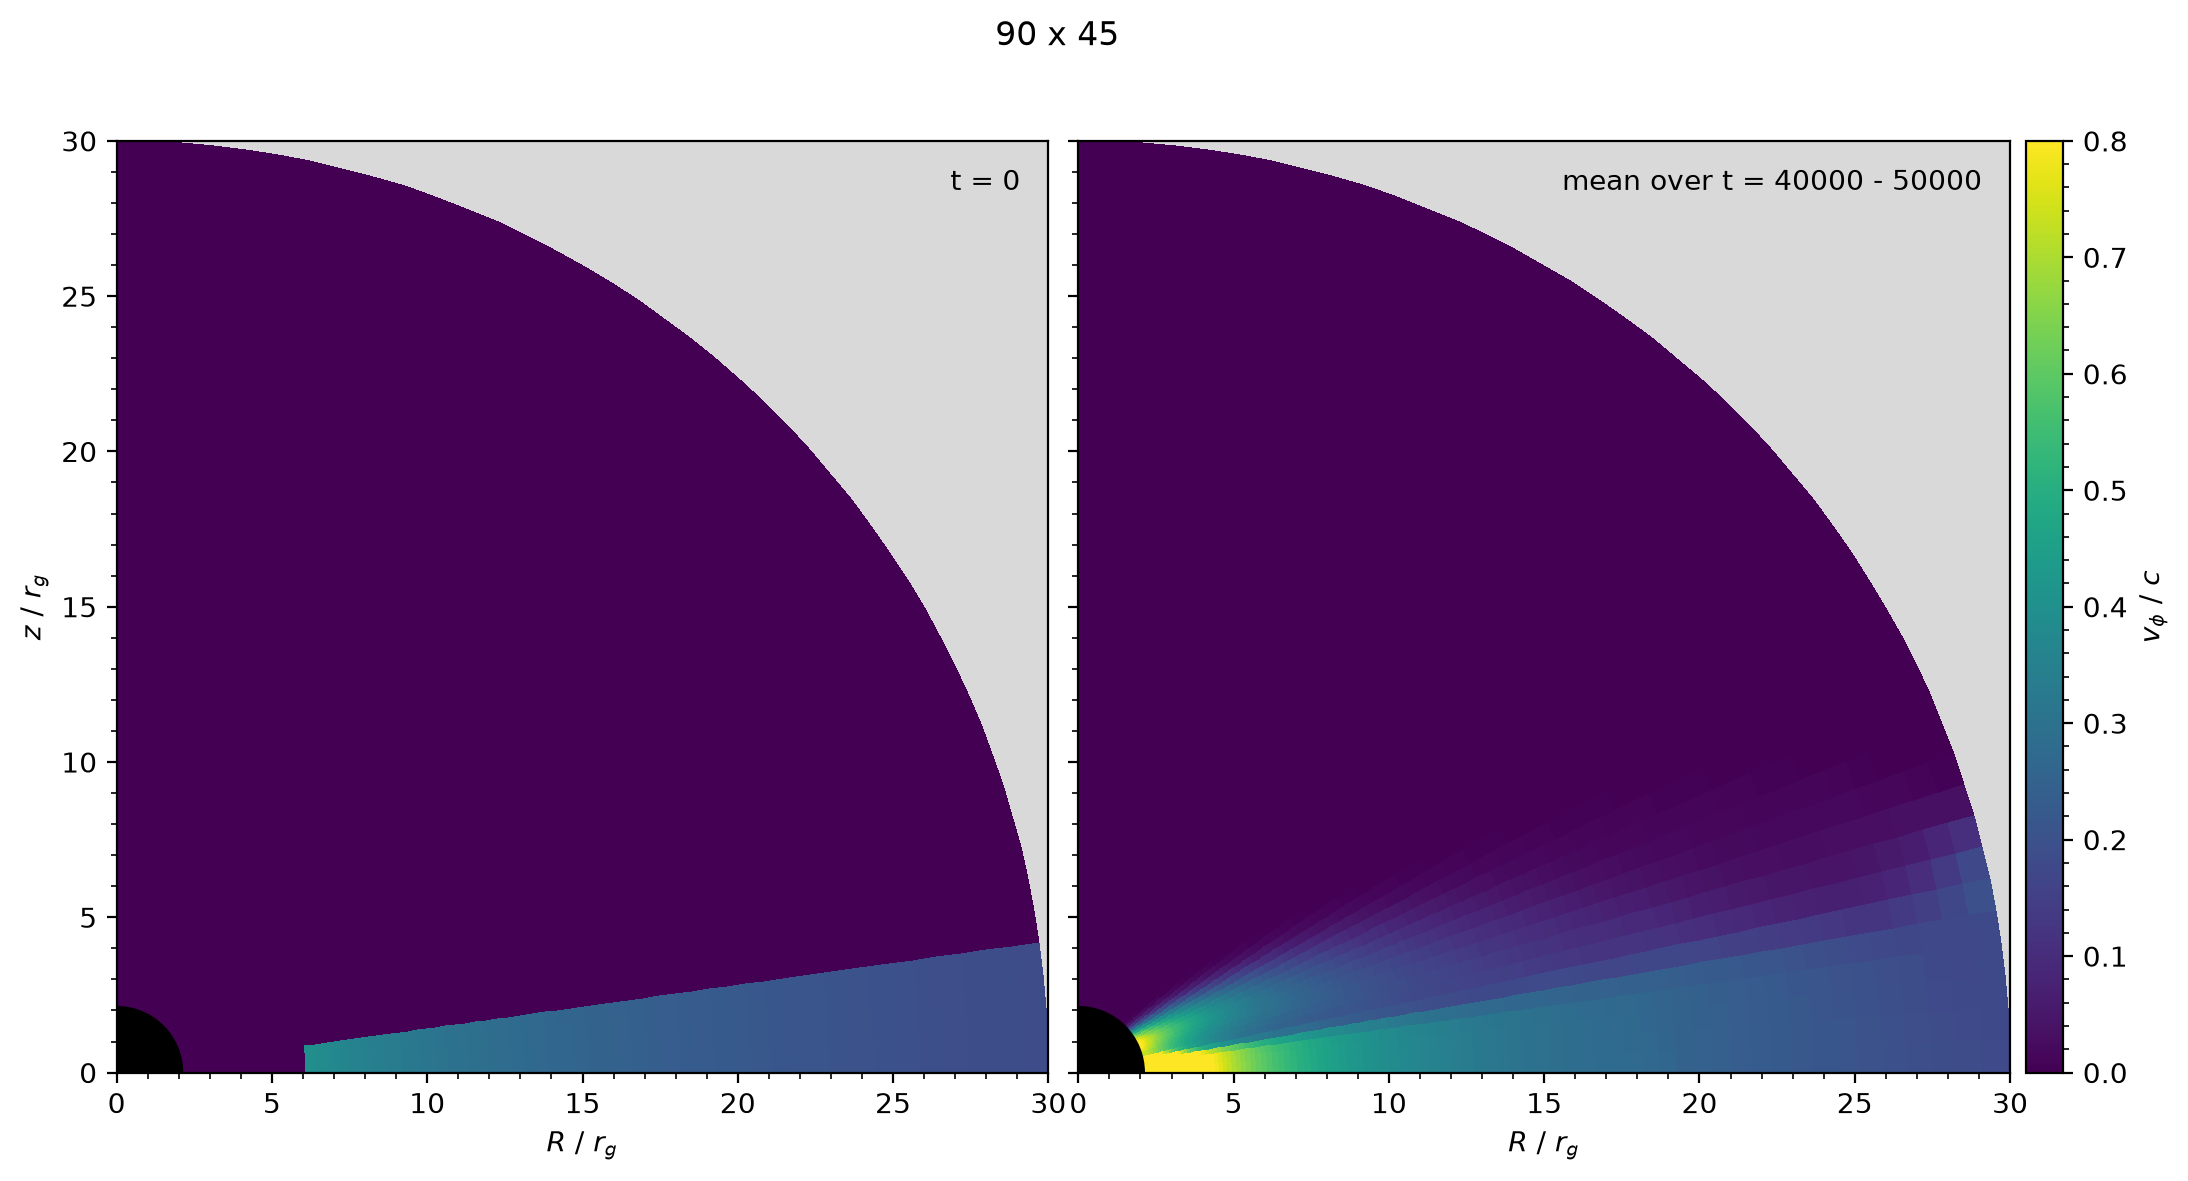

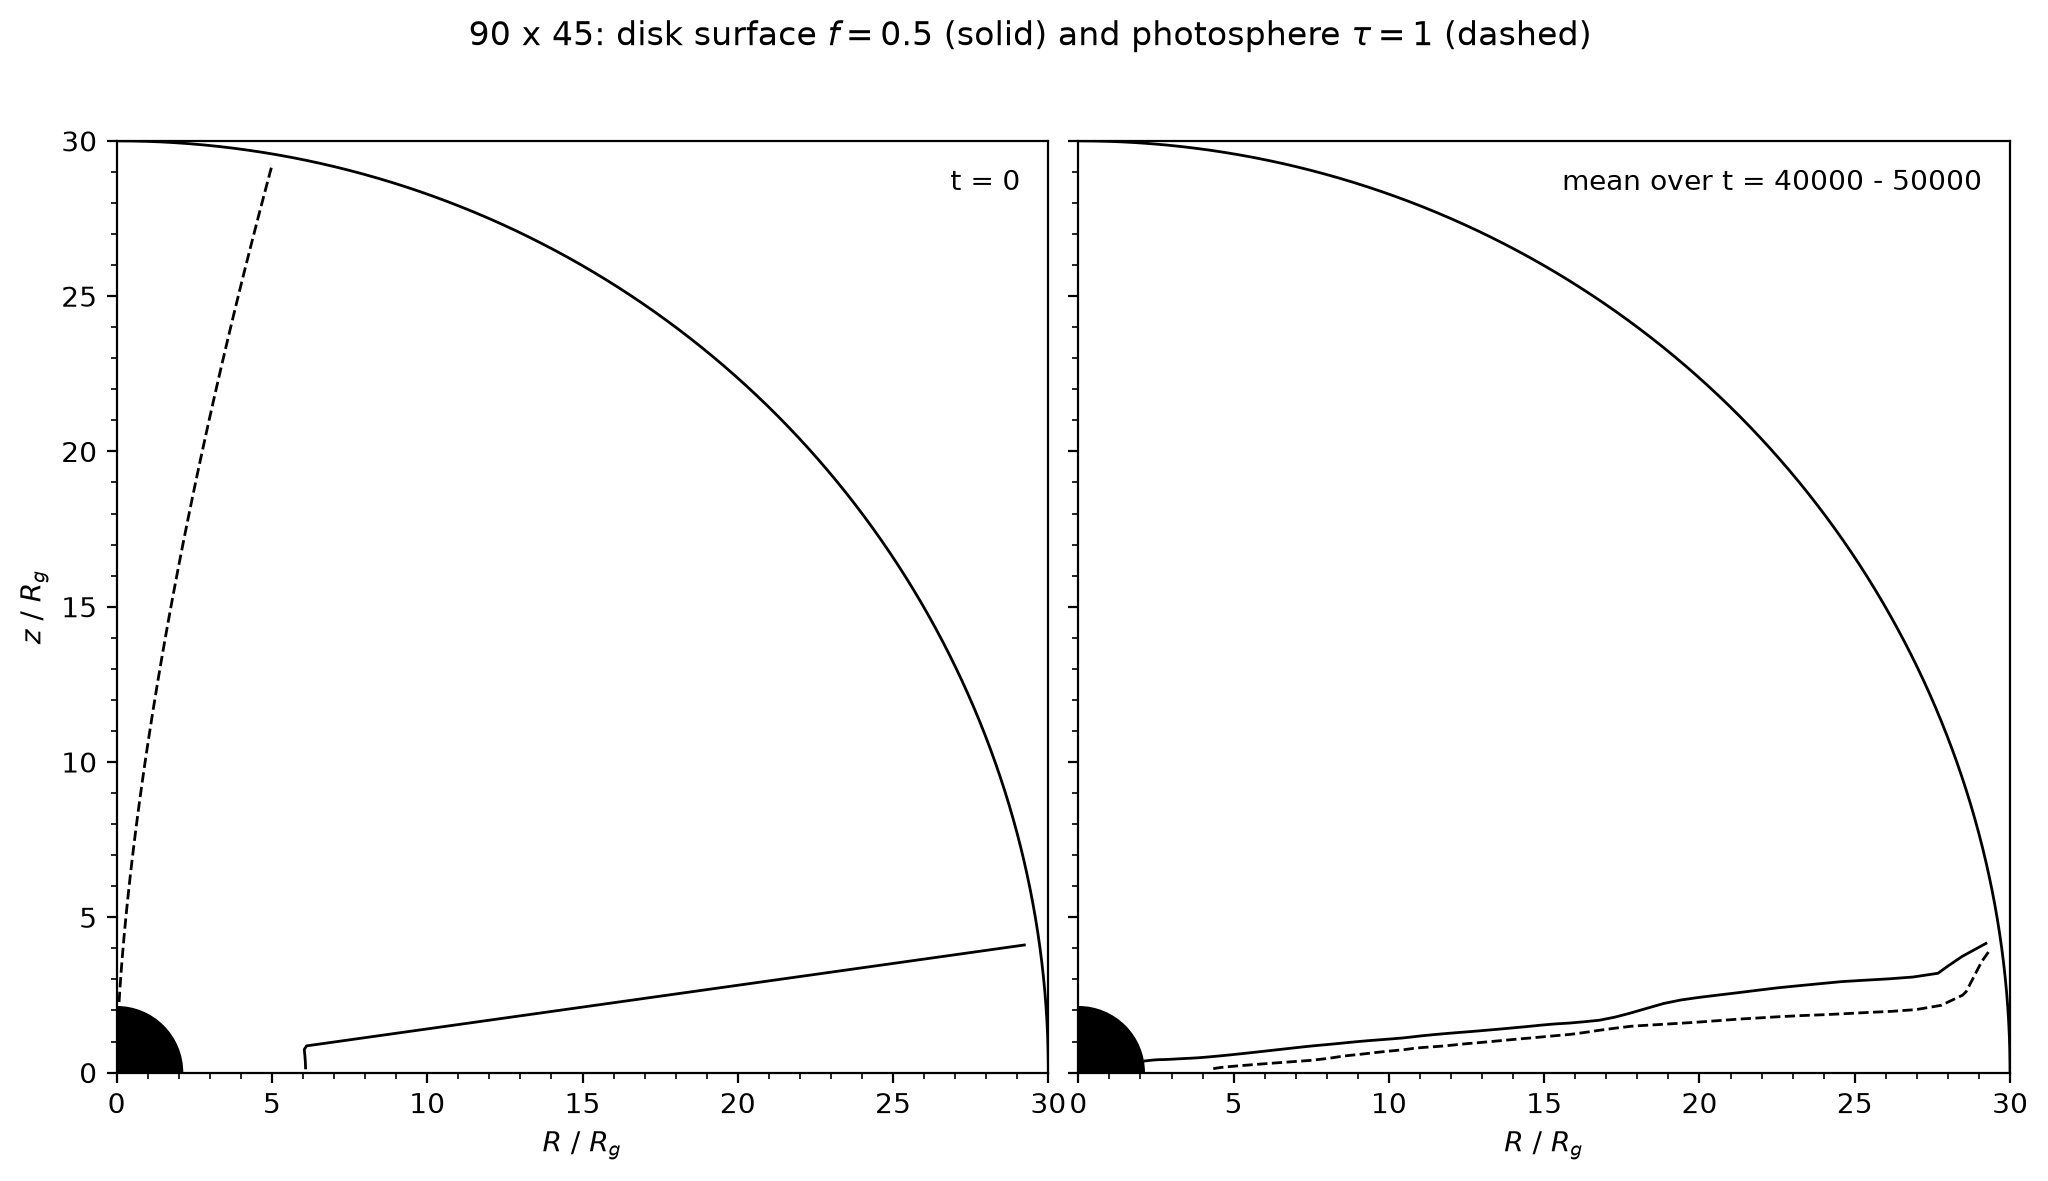

In [23]:
full_domain(RUN, MAIN_PATH, MAIN_GEO)
if REF is not None:
    full_domain(REF, REF_PATH, REF_GEO)

#### 1.2. Evolution

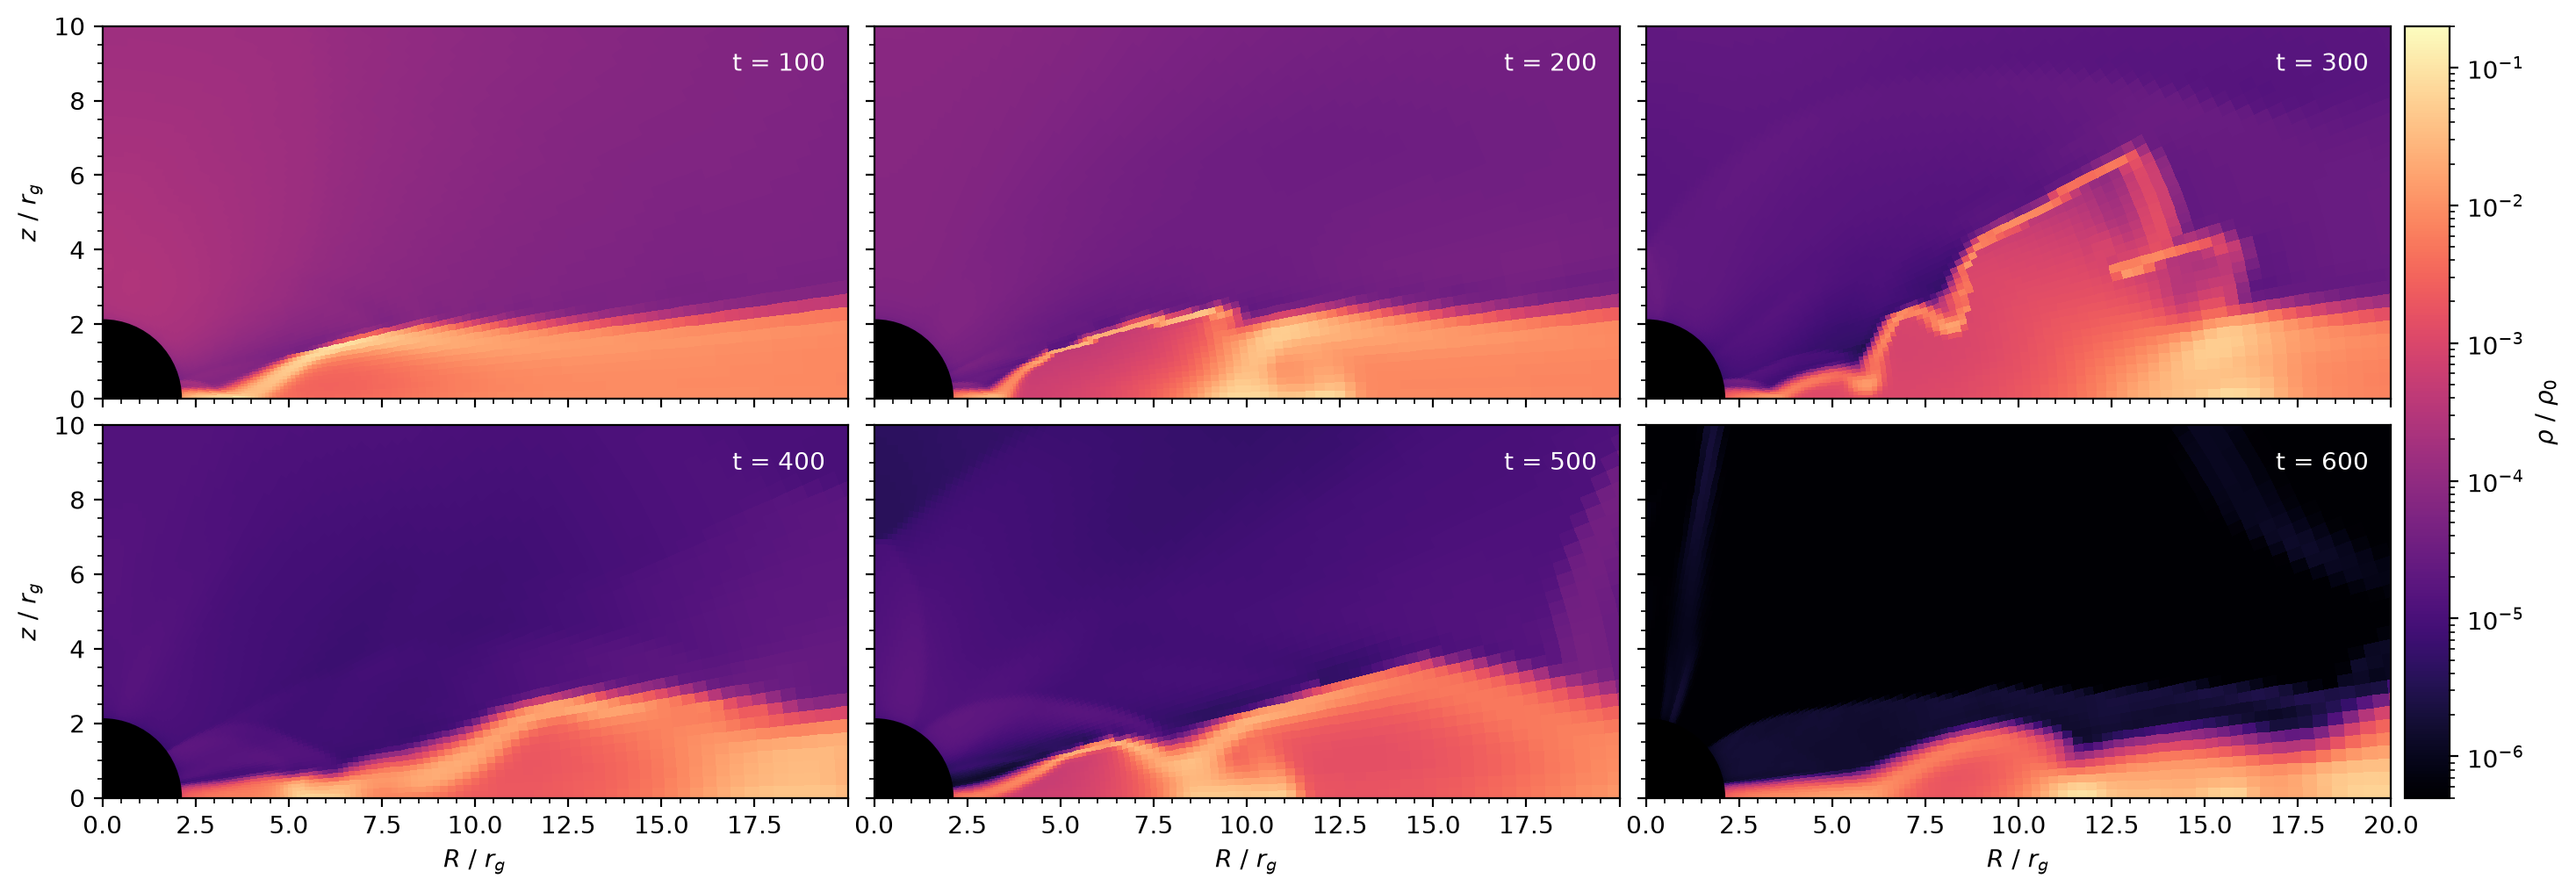

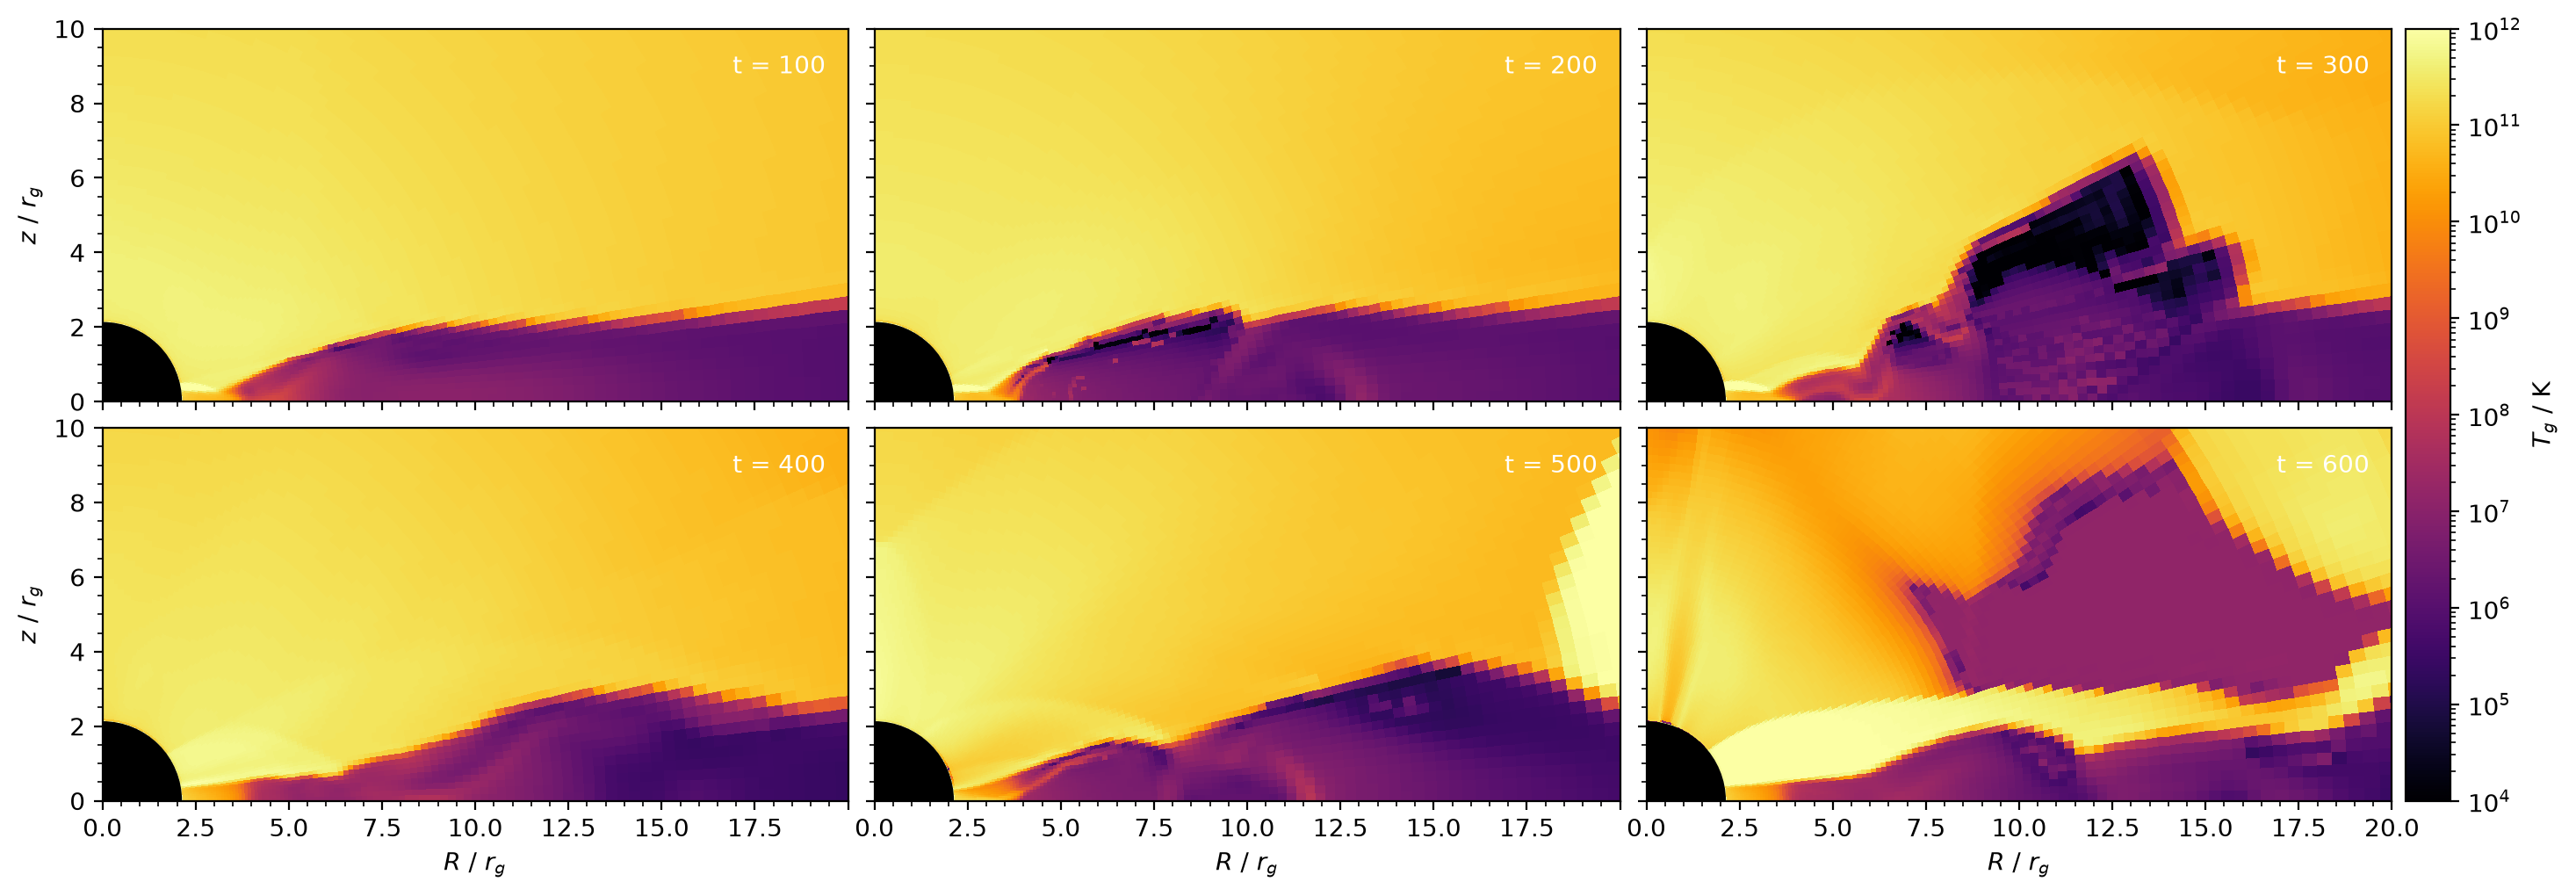

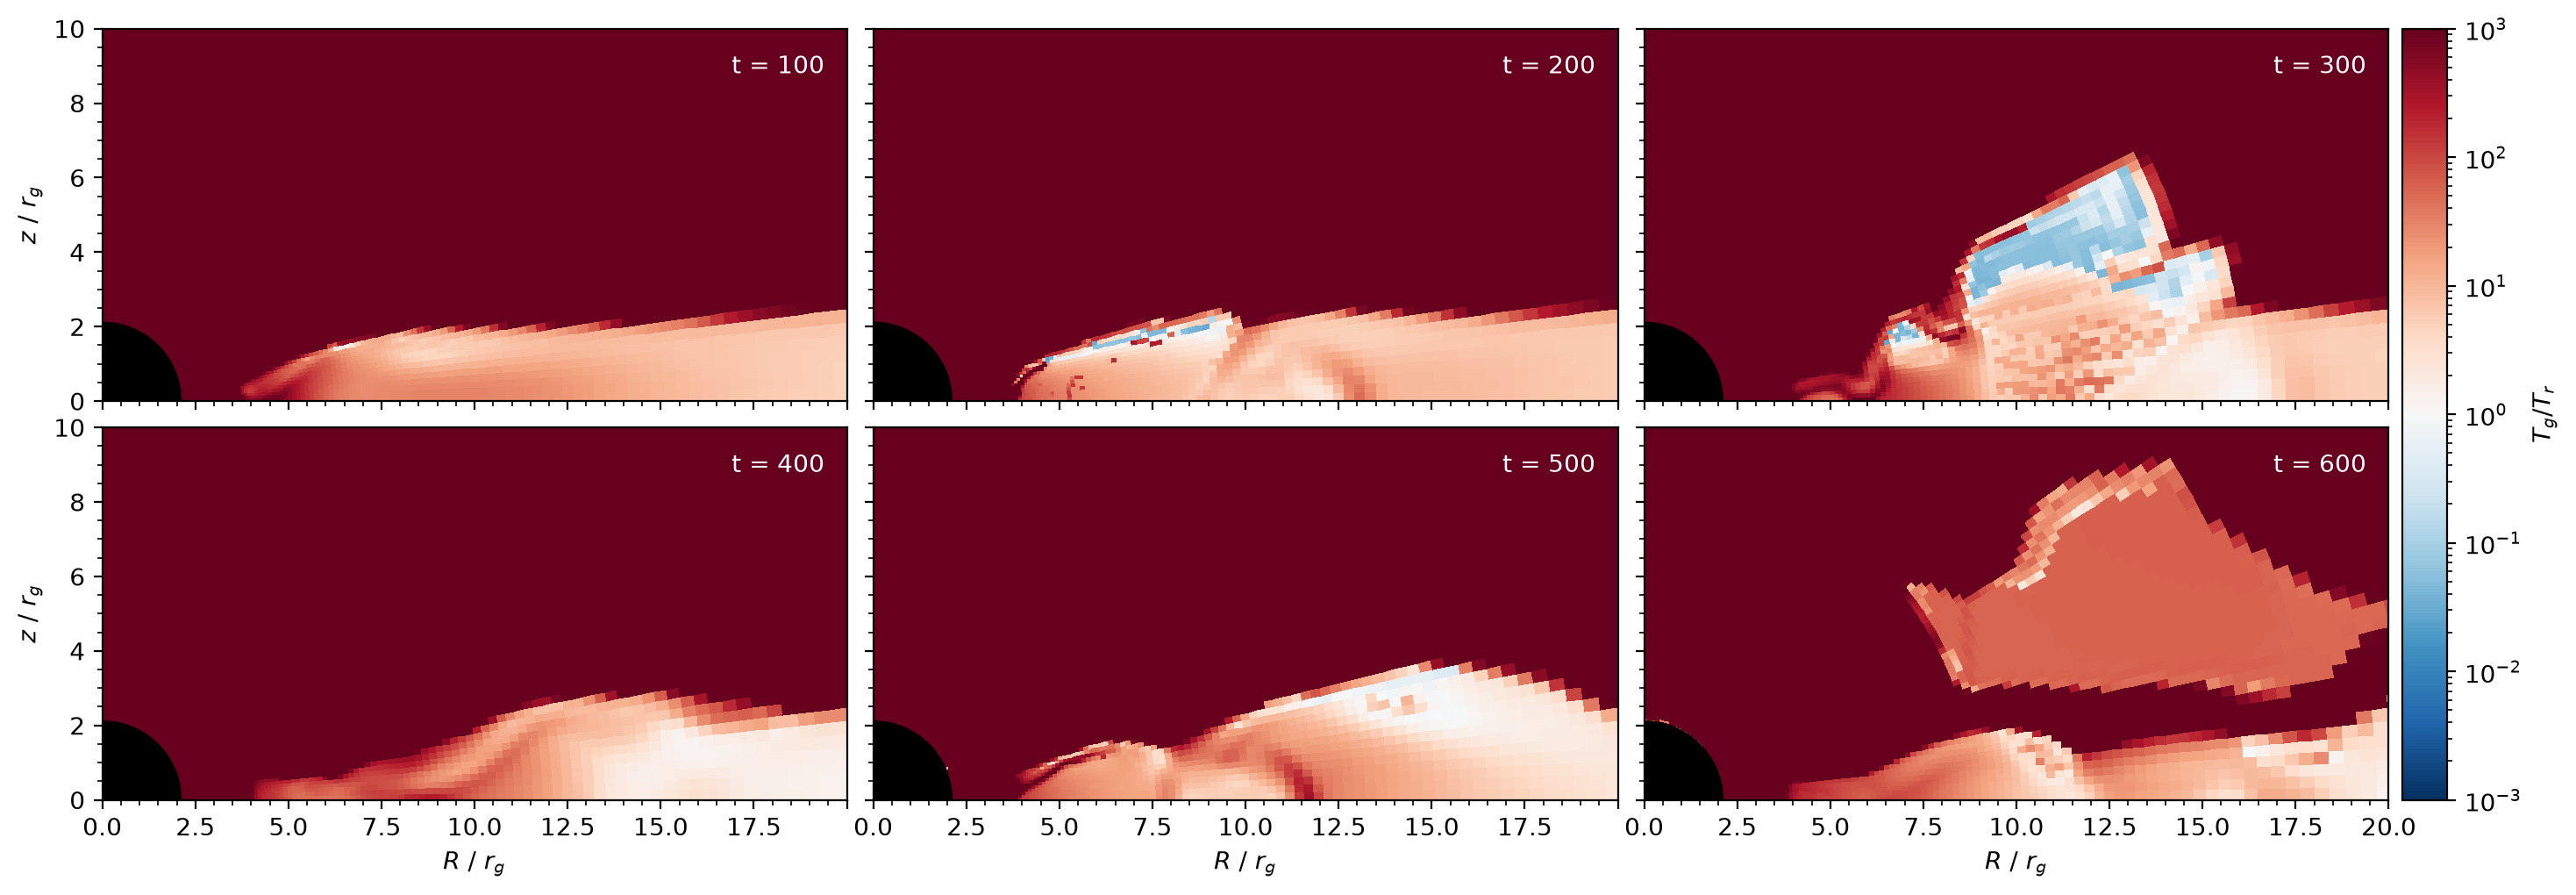

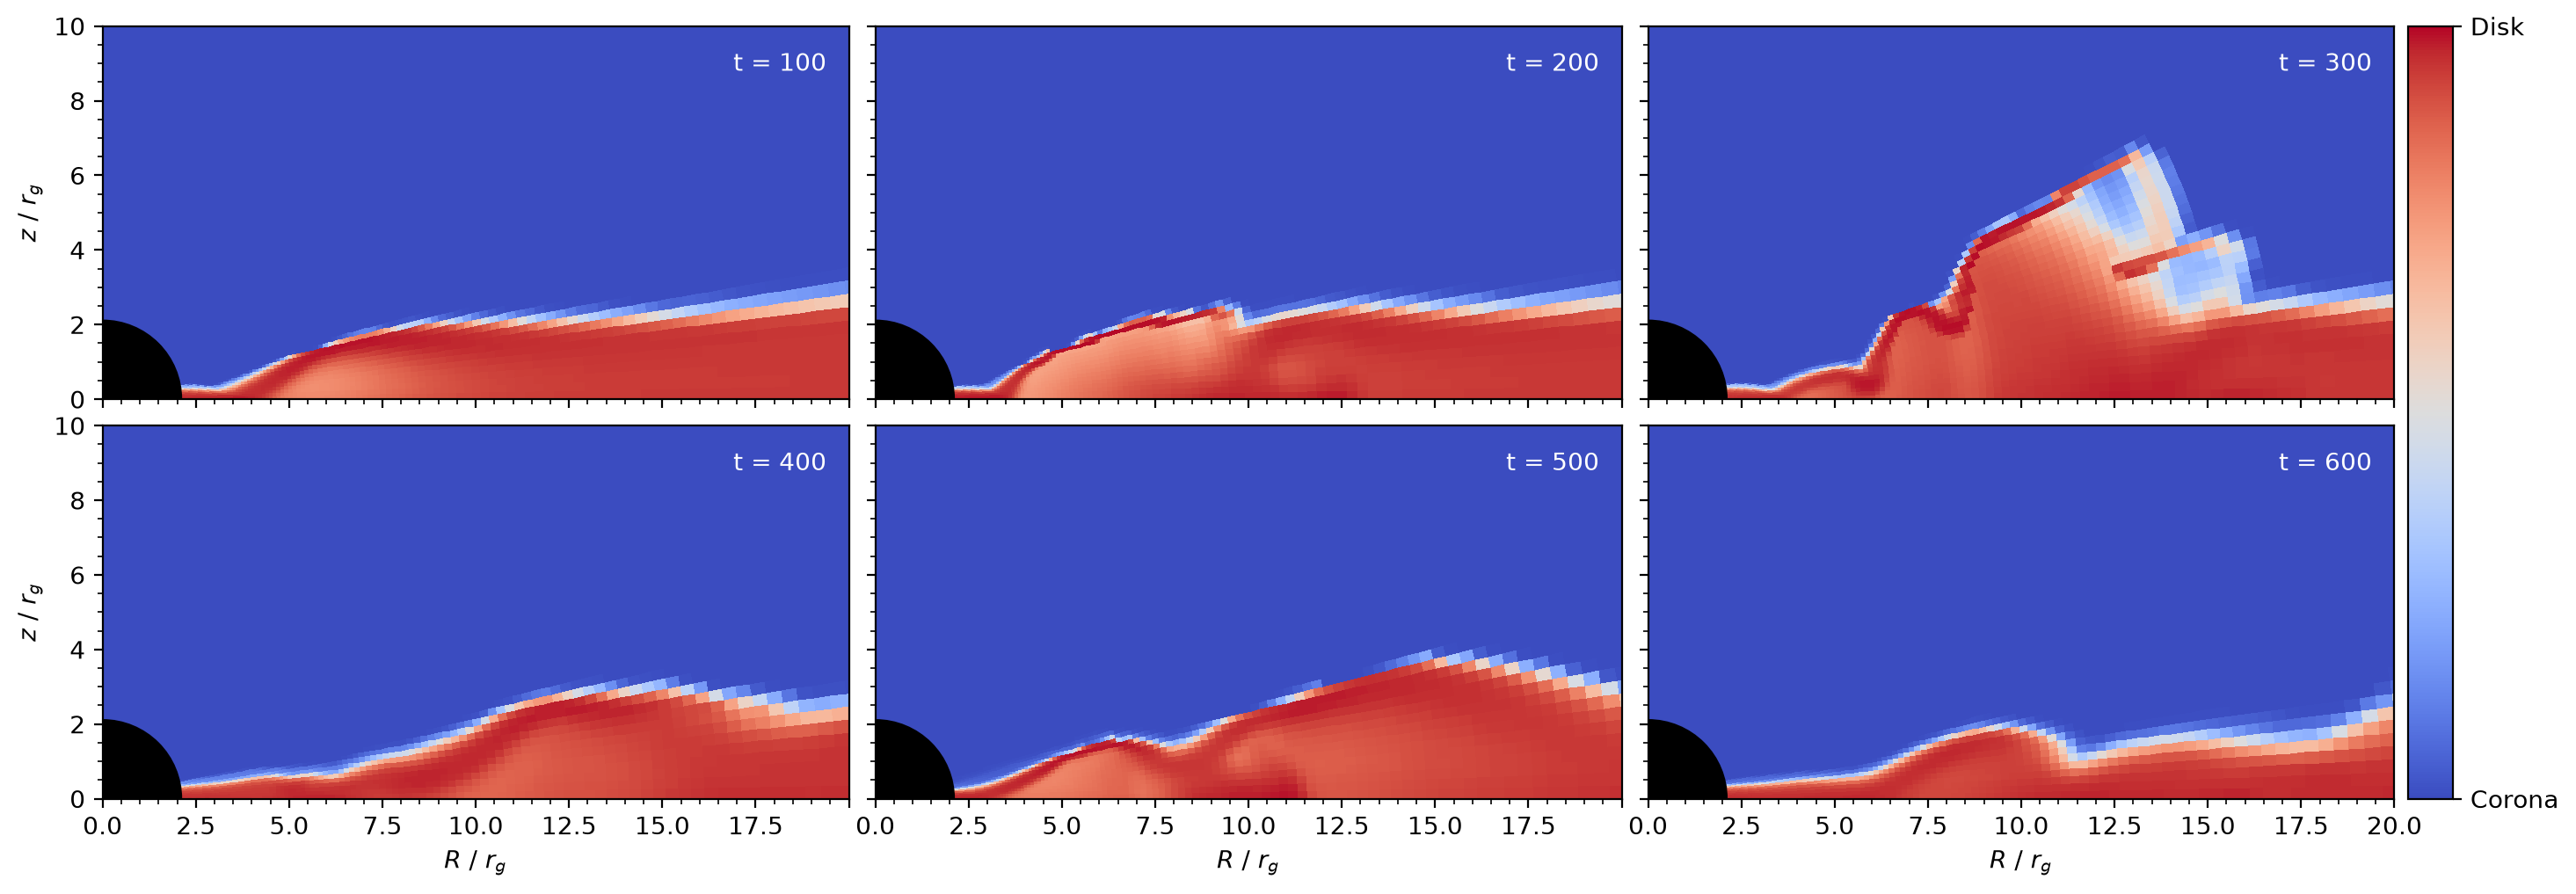

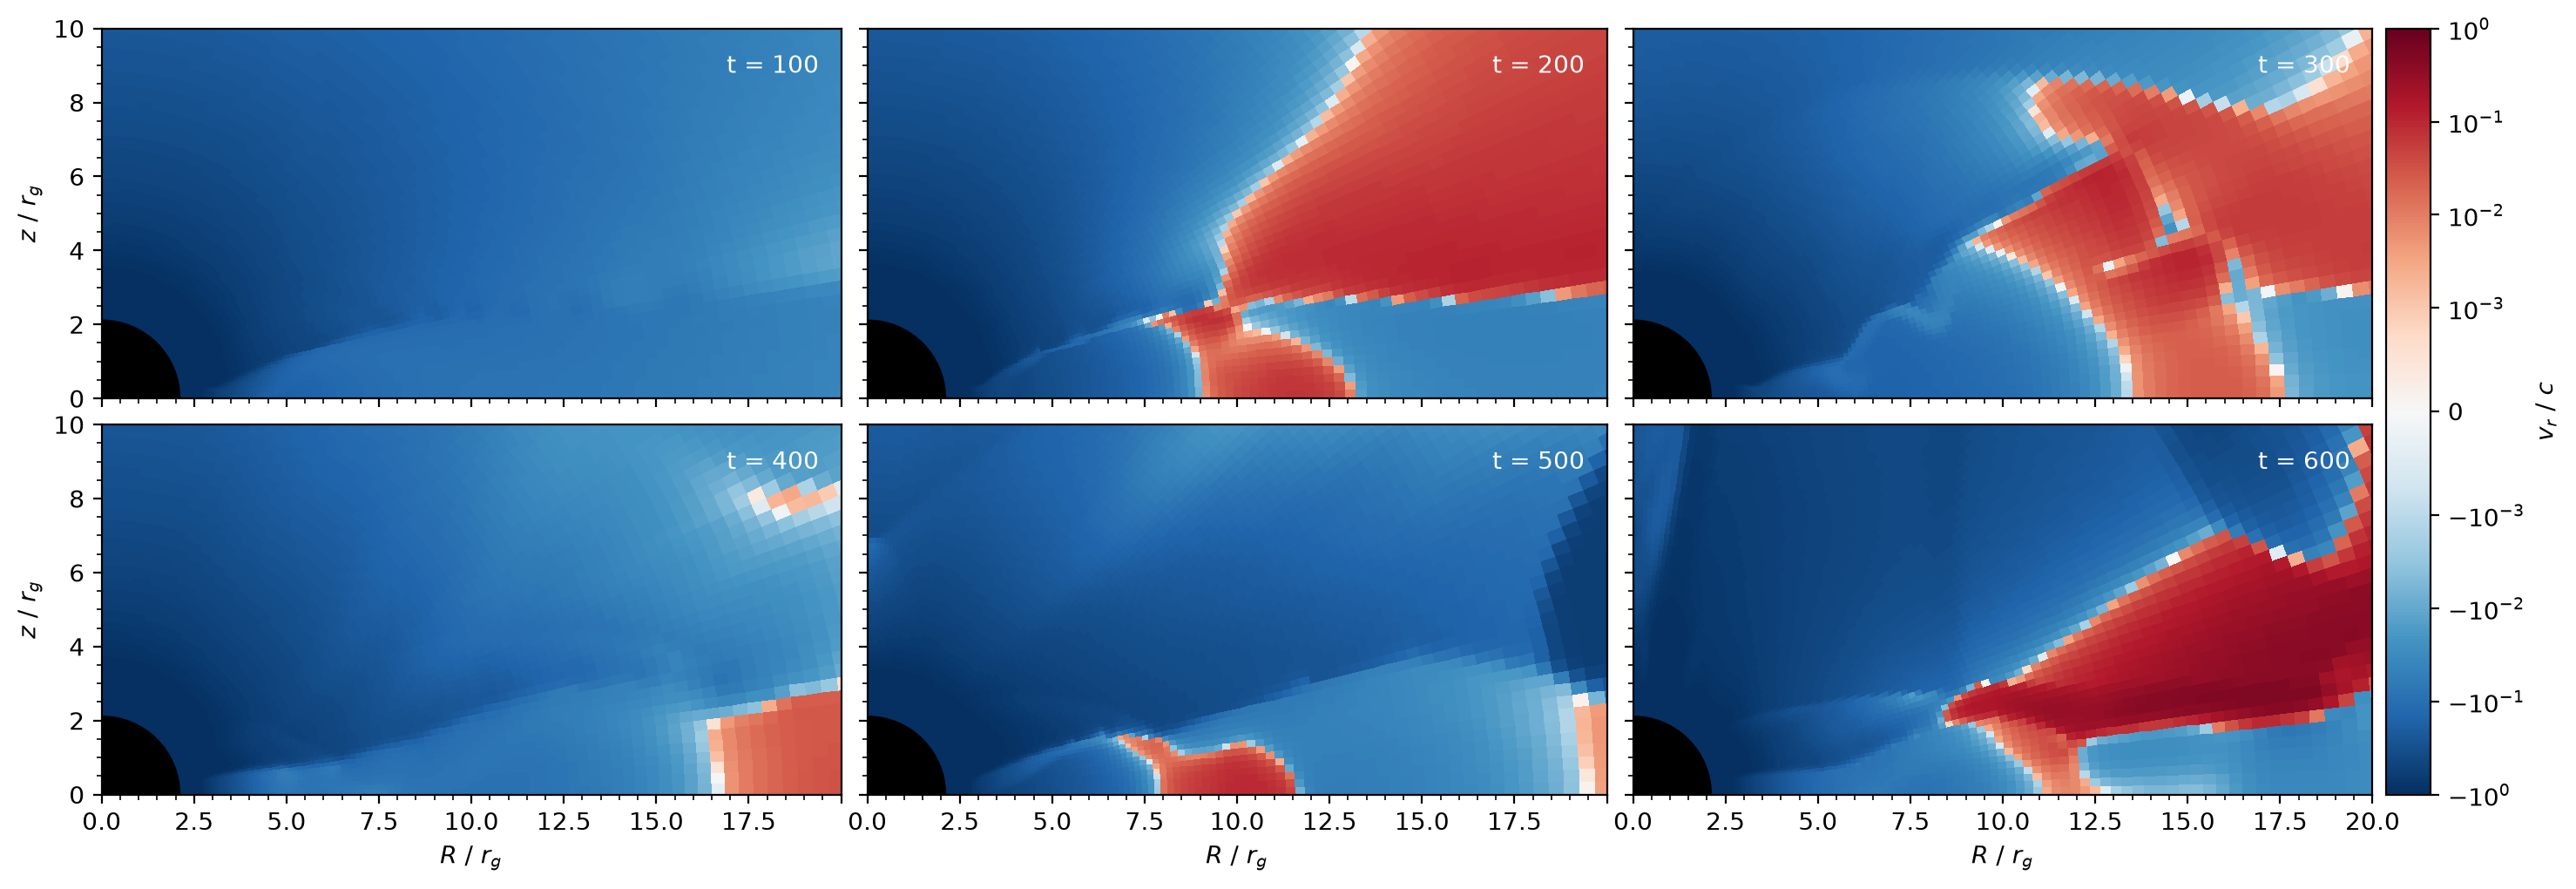

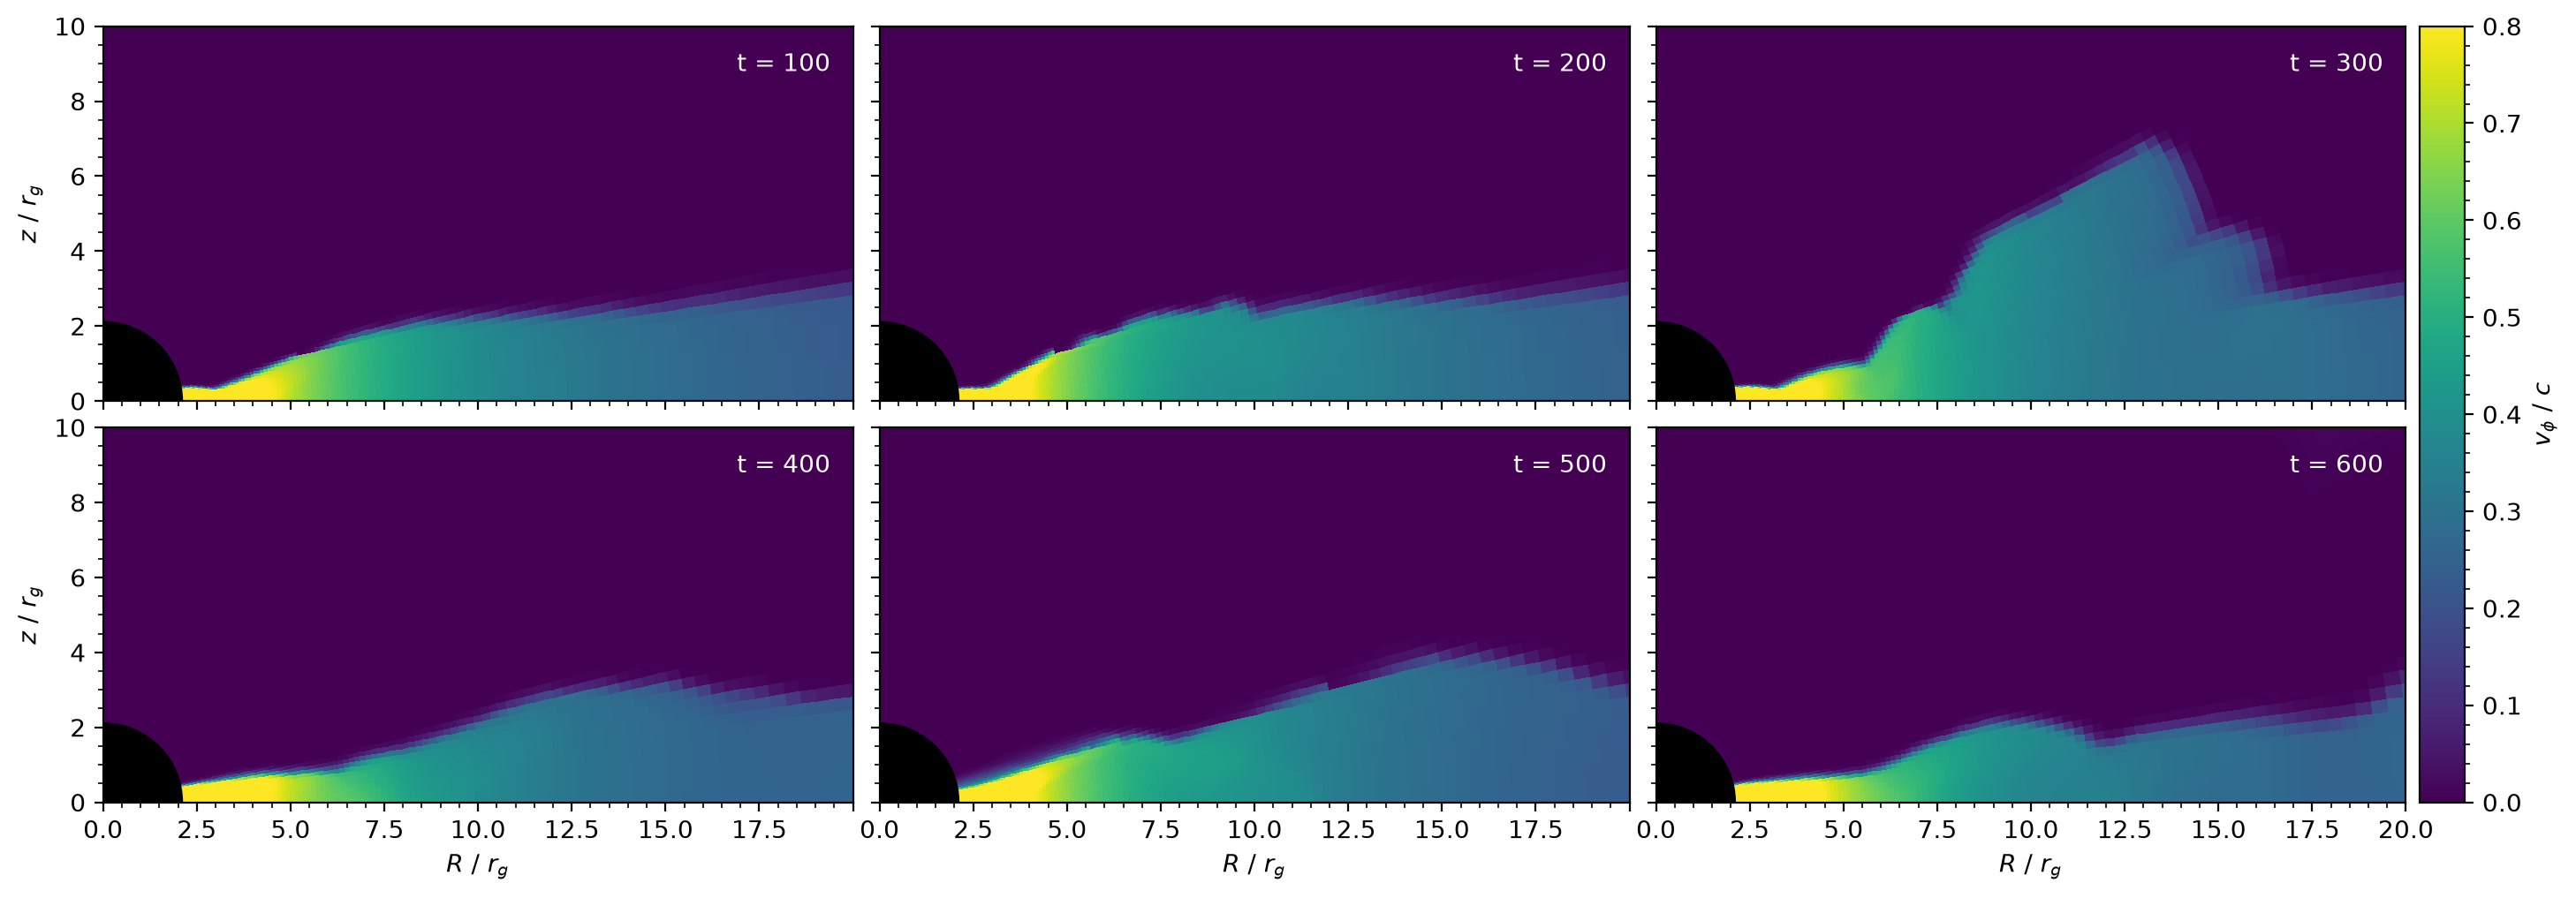

In [30]:
snapshot_rows(T_EARLY)

### 2. Relaxation